# Mon Pokédex Pokémon : notebook 1, données tabulaires (niveau 1)

**Module :** Fondements mathématiques de l'IA

**Objectif :** à partir des **6 statistiques de base** d'un Pokémon (PV, Attaque, Défense, Attaque spéciale, Défense spéciale, Vitesse) :

1. le ranger dans un **groupe** de Pokémon au profil similaire (clustering, non supervisé) ;
2. estimer sa **probabilité d'être légendaire** (classification binaire) ;
3. prédire son **type principal** `type1` (classification multiclasse, 18 classes).

Ces trois modèles alimentent l'application `app.py`.

**Plan du notebook**

| Partie | Contenu |
|---|---|
| 0 | Préparation : imports, chargement, nettoyage, fuite de données |
| 1 | Exploration des données (EDA) |
| 2 | Clustering : K-means, CAH, GMM, ACP |
| 3 | Prédiction du statut légendaire |
| 4 | Prédiction du type |
| 5 | Synthèse et choix des modèles |

**Reproductibilité :** toutes les opérations aléatoires utilisent `random_state = 42` (défini une seule fois dans `src/config.py`).

## 0. Préparation

### 0.1 Imports

Le code réutilisable est dans `src/`. Ainsi, le notebook, le script d'entraînement `src/train.py` et l'application utilisent **exactement** le même nettoyage et les mêmes listes de colonnes.

In [1]:
import sys
from pathlib import Path

# Permet d'importer le package src/ depuis le dossier notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (RANDOM_STATE, STATS, PHYSICAL, STAT_LABELS,
                        LEAKY_COLS, TARGET_LEGENDARY, TARGET_TYPE, TYPE_FR)
from src.preprocessing import load_raw, clean, quality_report, leaky_columns, NO_TYPE2
from src.viz import (set_style, save_fig, LEG_PALETTE, LEG_LABELS, COLOR_LEG,
                     COLOR_NON_LEG, CMAP_SEQ, CMAP_DIV, SERIES, INK_2, MUTED)

set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 2)
np.random.seed(RANDOM_STATE)
LABELS6 = [STAT_LABELS[s] for s in STATS]
print("random_state =", RANDOM_STATE)

random_state = 42


### 0.2 Chargement des données brutes

Dataset Kaggle « The Complete Pokemon Dataset » (Rounak Banik) : 801 Pokémon des générations 1 à 7. Les données ont été extraites du site serebii.net.

In [2]:
raw = load_raw()
print(f"{raw.shape[0]} lignes × {raw.shape[1]} colonnes")
raw[["pokedex_number", "name", "type1", "type2", *STATS, "base_total",
     "height_m", "weight_kg", "generation", "is_legendary"]].head()

801 lignes × 41 colonnes


,pokedex_number,name,type1,type2,hp,attack,defense,sp_attack,sp_defense,speed,base_total,height_m,weight_kg,generation,is_legendary
0,1,Bulbasaur,grass,poison,45,49,49,65,65,45,318,0.7,6.9,1,0
1,2,Ivysaur,grass,poison,60,62,63,80,80,60,405,1.0,13.0,1,0
2,3,Venusaur,grass,poison,80,100,123,122,120,80,625,2.0,100.0,1,0
3,4,Charmander,fire,NaN,39,52,43,60,50,65,309,0.6,8.5,1,0
4,5,Charmeleon,fire,NaN,58,64,58,80,65,80,405,1.1,19.0,1,0


### 0.3 Contrôle qualité et nettoyage

Trois points à surveiller :

1. **`capture_rate` est stocké comme du texte** à cause d'une seule valeur mal formée (Minior). Ce Pokémon a deux formes, avec deux taux de capture. On garde le premier nombre (30). La colonne ne servira de toute façon pas aux modèles (voir 0.4).
2. **`type2` manquant** pour 384 Pokémon. Ce n'est pas une donnée perdue : ces Pokémon n'ont qu'**un seul type**. On remplace donc la valeur par la modalité `"aucun"` au lieu de l'imputer.
3. **`height_m` et `weight_kg` manquants pour 20 Pokémon.** Ce sont presque tous des Pokémon qui ont une **forme d'Alola** (Rattata, Vulpix, Exeggutor…), plus Hoopa et Lycanroc, qui ont plusieurs formes. Le site source n'a pas su choisir une seule valeur. On **ne les remplit pas ici** : l'imputation par la médiane se fera dans le *pipeline*, avec la médiane du **train uniquement** (voir 0.4).

In [3]:
bad = raw.loc[pd.to_numeric(raw["capture_rate"], errors="coerce").isna(),
              ["name", "capture_rate"]]
print("Valeur non numérique de capture_rate :")
display(bad)

df = clean(raw)
report = quality_report(df)
print("Valeurs manquantes après nettoyage :", report["manquants"])
print("Pokémon sans second type      :", report["sans_type2"])
print("Doublons de nom               :", report["doublons_nom"])
print("Sans taille ni poids          :", ", ".join(report["pokemon_sans_taille_poids"]))

Valeur non numérique de capture_rate :


,name,capture_rate
773,Minior,30 (Meteorite)255 (Core)


Valeurs manquantes après nettoyage : {'height_m': 20, 'weight_kg': 20}
Pokémon sans second type      : 384
Doublons de nom               : 0
Sans taille ni poids          : Rattata, Raticate, Raichu, Sandshrew, Sandslash, Vulpix, Ninetales, Diglett, Dugtrio, Meowth, Persian, Geodude, Graveler, Golem, Grimer, Muk, Exeggutor, Marowak, Hoopa, Lycanroc


### 0.4 Choix des variables et fuite de données

> **Fuite de données (*data leakage*) :** le modèle utilise, pendant l'entraînement, une information qu'il **n'aura pas** au moment de prédire, ou qui contient déjà la réponse. Les scores obtenus sont alors excellents mais trompeurs : ils s'effondrent en conditions réelles.

Dans l'application, l'utilisateur ne saisit **que les 6 statistiques de base**. Les modèles n'ont donc le droit d'utiliser que ces 6 variables. La taille et le poids seront testés comme une **variante** à comparer.

Toutes les autres colonnes sont exclues, chacune pour une raison précise :

In [4]:
excl = pd.DataFrame({"colonne": list(LEAKY_COLS), "raison de l'exclusion": list(LEAKY_COLS.values())})
against = [c for c in df.columns if c.startswith("against_")]
excl.loc[len(excl)] = [f"against_* ({len(against)} colonnes)",
                       "dégâts reçus par type d'attaque : fonction directe de (type1, type2)"]
print(f"{len(leaky_columns(raw))} colonnes exclues au total")
excl

29 colonnes exclues au total


,colonne,raison de l'exclusion
0,capture_rate,fixé par le jeu : quasi toujours 3 pour les lé...
1,base_egg_steps,nombre de pas pour éclore : très élevé (~30 00...
2,base_happiness,bonheur de base : souvent 0 ou 35 pour les lég...
3,experience_growth,courbe d'XP : « lente » pour presque tous les ...
4,percentage_male,"manquant pour les Pokémon asexués, dont la plu..."
5,classfication,texte descriptif (ex. « Legendary Pokémon »)
6,pokedex_number,les légendaires sont regroupés en fin de génér...
7,base_total,"somme exacte des 6 stats : colonne redondante,..."
8,abilities,talents spécifiques aux légendaires (ex. « Pre...
9,japanese_name,"identifiant, aucune information généralisable"


**Vérification chiffrée : ces colonnes « trichent » vraiment.** Une règle naïve d'une ligne, sans aucun apprentissage, suffit à repérer presque tous les légendaires :

In [5]:
regles = {
    "capture_rate <= 3": df["capture_rate"] <= 3,
    "base_egg_steps >= 20480": df["base_egg_steps"] >= 20480,
    "percentage_male manquant (asexué)": df["percentage_male"].isna(),
}
lignes = []
for nom, pred in regles.items():
    vp = (pred & (df[TARGET_LEGENDARY] == 1)).sum()
    lignes.append({"règle": nom,
                   "rappel (légendaires trouvés)": vp / df[TARGET_LEGENDARY].sum(),
                   "précision (prédits vraiment légendaires)": vp / pred.sum()})
pd.DataFrame(lignes).set_index("règle").style.format("{:.0%}")

,rappel (légendaires trouvés),précision (prédits vraiment légendaires)
règle,,
capture_rate <= 3,76%,91%
base_egg_steps >= 20480,90%,97%
percentage_male manquant (asexué),90%,64%


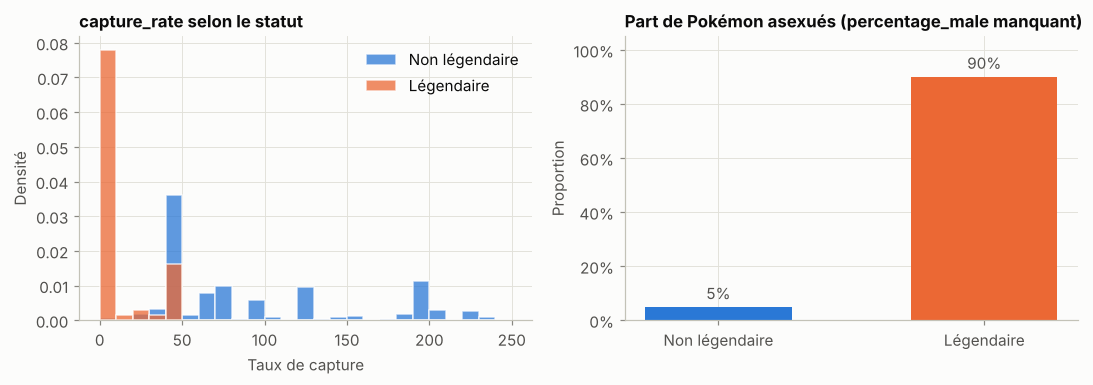

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))

ax = axes[0]
for k in (0, 1):
    vals = df.loc[df[TARGET_LEGENDARY] == k, "capture_rate"]
    ax.hist(vals, bins=np.arange(0, 260, 10), color=LEG_PALETTE[k], alpha=0.75,
            label=LEG_LABELS[k], density=True, edgecolor="white", linewidth=1)
ax.set(title="capture_rate selon le statut", xlabel="Taux de capture", ylabel="Densité")
ax.legend()

ax = axes[1]
taux = df["percentage_male"].isna().groupby(df[TARGET_LEGENDARY]).mean()
bars = ax.bar([LEG_LABELS[k] for k in taux.index], taux.values,
              color=[LEG_PALETTE[k] for k in taux.index], width=0.55)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in taux.values], padding=3, color=INK_2)
ax.set(title="Part de Pokémon asexués (percentage_male manquant)", ylim=(0, 1.05),
       ylabel="Proportion")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.tight_layout()
save_fig(fig, "01_fuite_de_donnees")
plt.show()

**Conclusion.** `capture_rate` vaut 3 pour 53 des 70 légendaires, et `base_egg_steps` dépasse 20 000 pas pour 63 d'entre eux. Avec ces variables, un modèle afficherait des scores quasi parfaits sans rien apprendre des **statistiques**, et il serait inutilisable dans l'appli, qui ne reçoit pas ces informations. Les colonnes `against_*` posent le même problème pour la prédiction du type : elles sont **calculées à partir du type**.

`base_total` est exclue pour une autre raison : c'est **exactement** la somme des 6 stats. Une variable qui est une combinaison linéaire exacte des autres n'apporte aucune information nouvelle. En régression logistique, elle crée de plus une colinéarité parfaite : les coefficients ne sont plus identifiables. Elle reste en revanche très utile pour l'**analyse**.

*Remarque (voir 3.5)* : la colonne `base_total` du CSV n'est pas utilisée telle quelle. En revanche, le **total peut être recalculé à partir des 6 stats saisies**, à l'intérieur du pipeline (`AddTotal`). Ce n'est pas une fuite, puisque l'appli dispose des mêmes 6 stats. Cette variable est inutile pour un modèle linéaire, mais très utile pour les arbres.

## 1. Exploration des données (EDA)

### 1.1 Distribution des 6 statistiques

In [7]:
desc = df[STATS].describe().T
desc["asymétrie"] = df[STATS].skew()
desc.rename(index=STAT_LABELS)

,count,mean,std,min,25%,50%,75%,max,asymétrie
PV,801.0,68.96,26.58,1.0,50.0,65.0,80.0,255.0,1.83
Attaque,801.0,77.86,32.16,5.0,55.0,75.0,100.0,185.0,0.53
Défense,801.0,73.01,30.77,5.0,50.0,70.0,90.0,230.0,1.12
Att. Spé.,801.0,71.31,32.35,10.0,45.0,65.0,91.0,194.0,0.78
Déf. Spé.,801.0,70.91,27.94,20.0,50.0,66.0,90.0,230.0,0.87
Vitesse,801.0,66.33,28.91,5.0,45.0,65.0,85.0,180.0,0.44


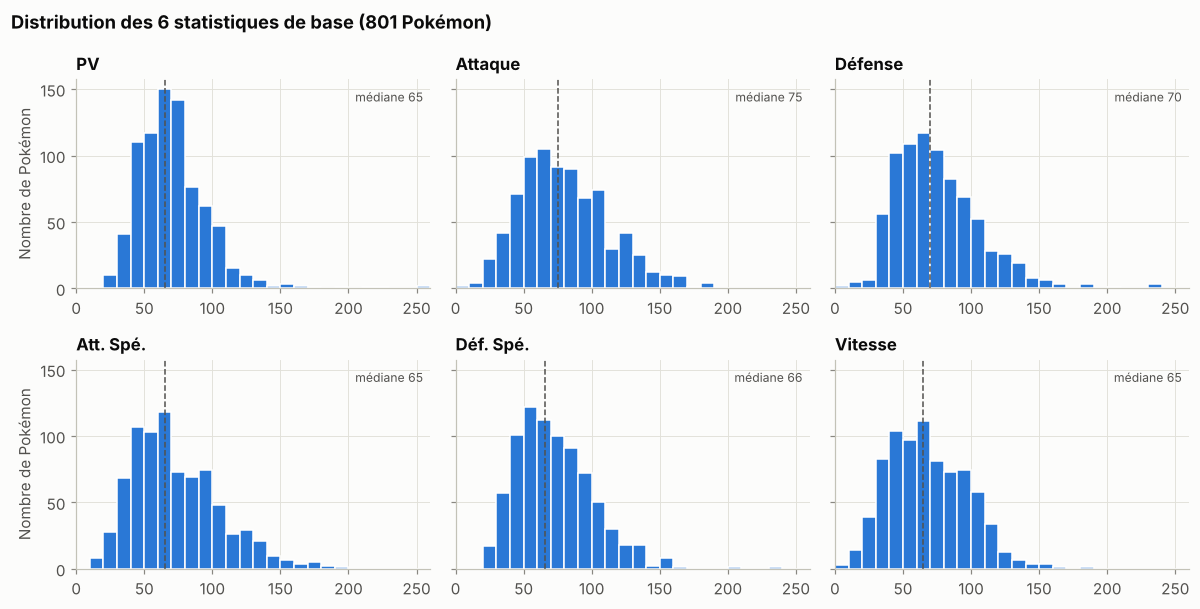

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6), sharey=True)
for ax, s in zip(axes.flat, STATS):
    ax.hist(df[s], bins=np.arange(0, 265, 10), color=COLOR_NON_LEG,
            edgecolor="white", linewidth=1)
    med = df[s].median()
    ax.axvline(med, color=INK_2, lw=1, ls="--")
    ax.text(0.98, 0.95, f"médiane {med:.0f}", transform=ax.transAxes,
            color=INK_2, fontsize=8, ha="right", va="top")
    ax.set_title(STAT_LABELS[s])
    ax.set_xlim(0, 260)
for ax in axes[:, 0]:
    ax.set_ylabel("Nombre de Pokémon")
fig.suptitle("Distribution des 6 statistiques de base (801 Pokémon)", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_distributions_stats")
plt.show()

In [9]:
# Valeurs extrêmes : qui sont les Pokémon hors normes ?
pd.DataFrame({STAT_LABELS[s]: df.nlargest(3, s).apply(lambda r: f"{r['name']} ({r[s]})", axis=1).values
              for s in STATS}, index=["1er", "2e", "3e"])

,PV,Attaque,Défense,Att. Spé.,Déf. Spé.,Vitesse
1er,Blissey (255),Heracross (185),Steelix (230),Mewtwo (194),Shuckle (230),Deoxys (180)
2e,Chansey (250),Kartana (181),Shuckle (230),Kyogre (180),Regice (200),Ninjask (160)
3e,Guzzlord (223),Groudon (180),Aggron (230),Rayquaza (180),Kyogre (160),Pheromosa (151)


**Lecture**

- Les 6 stats ont des **ordres de grandeur comparables** (moyennes de 66 à 78, écarts-types de 27 à 32). Elles ne sont pourtant **pas** sur la même échelle : les PV vont de 1 à 255, la Défense spéciale de 20 à 230.
- Toutes les distributions sont **asymétriques à droite** : beaucoup de Pokémon moyens et une queue de Pokémon très forts. C'est le cas surtout des **PV** (asymétrie 1,8) et de la **Défense** (1,1).
- Les valeurs extrêmes sont **réelles**, pas des erreurs : Leuphorie (Blissey, 255 PV), Caratroc (Shuckle, 230 en Défense et en Défense spéciale), Mewtwo (194 en Attaque spéciale). On les **garde**, car ils font partie de ce que l'appli doit savoir traiter.

**Conséquence : standardiser avant toute méthode fondée sur une distance.** On applique le z-score $z = \dfrac{x - \mu}{\sigma}$, où $\mu$ et $\sigma$ sont calculés **sur le train**. K-means, k-NN et SVM utilisent la distance euclidienne $d(\mathbf{x}, \mathbf{y}) = \sqrt{\sum_j (x_j - y_j)^2}$. Sans standardisation, une variable plus dispersée pèserait davantage dans la distance, sans que cela ait un sens.

**Remarque :** le dataset donne pour certains Pokémon les stats de leur **méga-évolution** (Florizarre : 625 au total, Dracaufeu : 634…). Il faudra le garder en tête lors de l'interprétation : ces Pokémon paraîtront « quasi légendaires ».

### 1.2 Les légendaires ont-ils des stats différentes ?

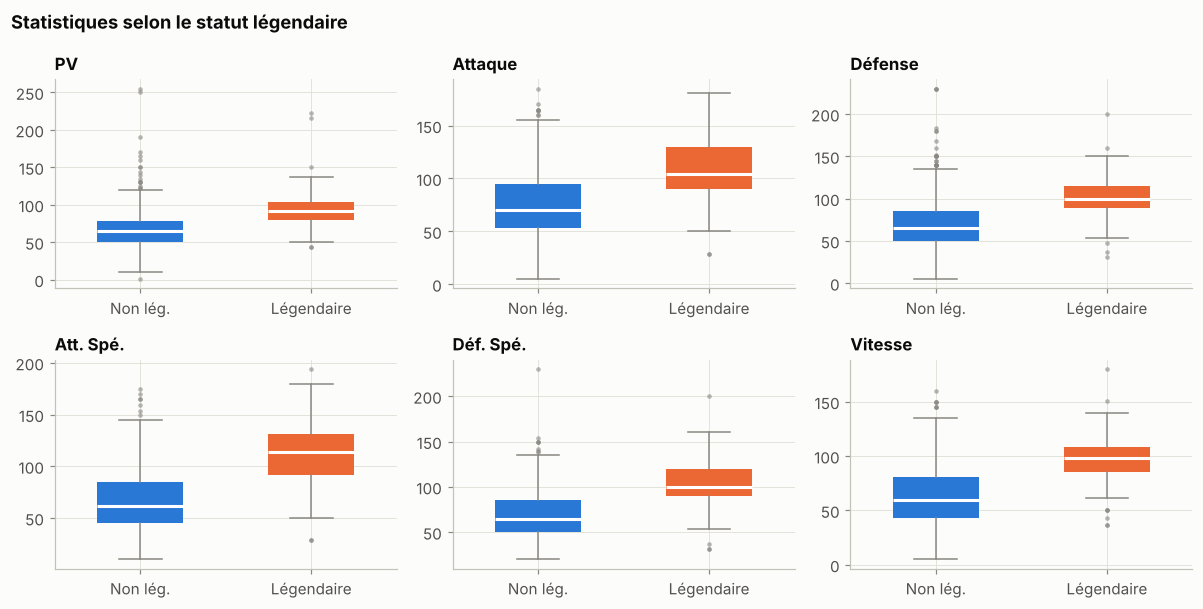

,PV,Attaque,Défense,Att. Spé.,Déf. Spé.,Vitesse,base_total
is_legendary,,,,,,,
Non légendaire,65.0,70.0,65.0,62.0,65.0,60.0,418.0
Légendaire,91.0,104.0,100.0,114.0,100.0,98.0,600.0


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(11, 5.6))
for ax, s in zip(axes.flat, STATS):
    data = [df.loc[df[TARGET_LEGENDARY] == k, s] for k in (0, 1)]
    bp = ax.boxplot(data, tick_labels=["Non lég.", "Légendaire"], widths=0.5,
                    patch_artist=True, medianprops=dict(color="white", lw=2),
                    flierprops=dict(marker="o", ms=3, mfc=MUTED, mec="none", alpha=0.6),
                    whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    for patch, k in zip(bp["boxes"], (0, 1)):
        patch.set_facecolor(LEG_PALETTE[k])
        patch.set_edgecolor("none")
    ax.set_title(STAT_LABELS[s])
fig.suptitle("Statistiques selon le statut légendaire", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "03_stats_par_statut")
plt.show()

df.groupby(TARGET_LEGENDARY)[STATS + ["base_total"]].median().rename(
    index=LEG_LABELS, columns=STAT_LABELS)

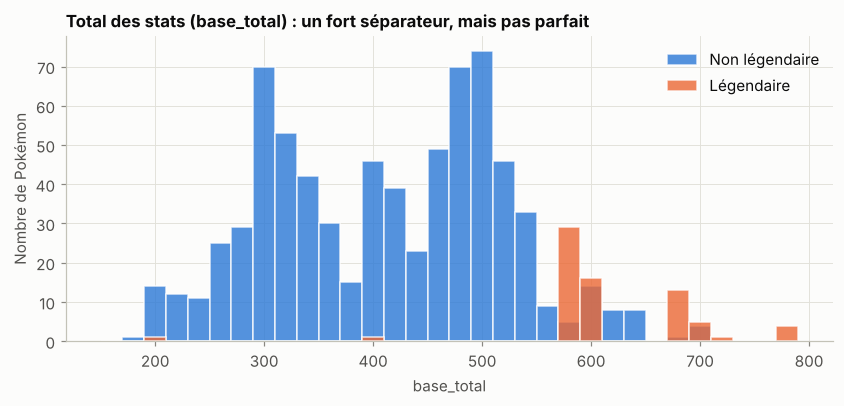

Non légendaires avec base_total >= 600 : 31
    Venusaur, Charizard, Blastoise, Alakazam, Gengar, Pinsir, Gyarados, Aerodactyl, Dragonite, Ampharos, Steelix, Scizor, Heracross, Houndoom, Tyranitar, Sceptile, Blaziken, Swampert, Gardevoir, Slaking, Aggron, Salamence, Metagross, Garchomp, Lucario, Gallade, Hydreigon, Greninja, Goodra, Wishiwashi, Kommo-o
Légendaires avec base_total < 570      : 2
    Cosmog (200), Cosmoem (400)


In [11]:
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(150, 800, 20)
for k in (0, 1):
    ax.hist(df.loc[df[TARGET_LEGENDARY] == k, "base_total"], bins=bins, alpha=0.8,
            color=LEG_PALETTE[k], label=LEG_LABELS[k], edgecolor="white", linewidth=1)
ax.set(title="Total des stats (base_total) : un fort séparateur, mais pas parfait",
       xlabel="base_total", ylabel="Nombre de Pokémon")
ax.legend()
save_fig(fig, "04_base_total_par_statut")
plt.show()

chev = df[(df[TARGET_LEGENDARY] == 0) & (df["base_total"] >= 600)]
faibles = df[(df[TARGET_LEGENDARY] == 1) & (df["base_total"] < 570)]
print(f"Non légendaires avec base_total >= 600 : {len(chev)}")
print("   ", ", ".join(chev['name']))
print(f"Légendaires avec base_total < 570      : {len(faibles)}")
print("   ", ", ".join(f"{n} ({t})" for n, t in faibles[['name', 'base_total']].values))

**Lecture**

- Les légendaires sont **nettement plus forts sur les 6 stats**. Leur total médian est de 600, contre 418 pour les autres. L'écart le plus marqué concerne l'**Attaque spéciale** (114 contre 62).
- La séparation n'est pourtant **pas parfaite**. Les deux histogrammes se chevauchent autour de 580–680, à cause de deux groupes de Pokémon :
  - des **non-légendaires très forts** : les « pseudo-légendaires » (Dracolosse, Tyranocif, Métalosse, Carchacrok…) et des méga-évolutions ;
  - quelques **légendaires faibles** : Cosmog (200) et Cosmovum (400), formes de bébé de Solgaleo et Lunala, et les Tokos et plusieurs Ultra-Chimères, à 570 tout juste.
- **Conséquence pour l'étape 3 :** les stats seules permettront une bonne prédiction, mais pas parfaite. Les erreurs seront prévisibles : des pseudo-légendaires pris pour des légendaires, et inversement. Ce chevauchement justifie aussi d'afficher une **probabilité** plutôt qu'un verdict oui/non.

### 1.3 Corrélations entre les statistiques

On calcule deux coefficients :

- **Pearson** $r = \dfrac{\mathrm{cov}(X, Y)}{\sigma_X \sigma_Y}$ mesure une relation **linéaire**. Il est sensible aux valeurs extrêmes.
- **Spearman** est la corrélation de Pearson calculée sur les **rangs**. Il mesure une relation **monotone** et résiste aux valeurs extrêmes (Leuphorie, Caratroc…).

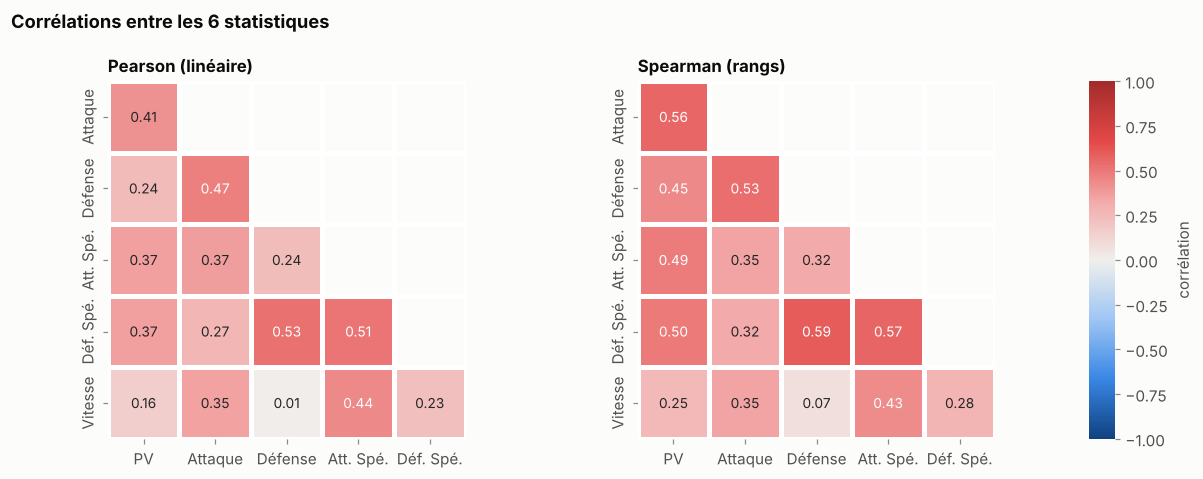

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(11, 4.4), gridspec_kw=dict(width_ratios=[1, 1, 0.05]))
for ax, meth, titre in zip(axes[:2], ["pearson", "spearman"], ["Pearson (linéaire)", "Spearman (rangs)"]):
    c = df[STATS].corr(method=meth)
    # on masque la diagonale (toujours 1) et le triangle supérieur (symétrique)
    mask = np.triu(np.ones_like(c, dtype=bool), k=0)
    sns.heatmap(c.iloc[1:, :-1], mask=mask[1:, :-1], annot=True, fmt=".2f", cmap=CMAP_DIV,
                vmin=-1, vmax=1, square=True, linewidths=2, linecolor="white",
                cbar=ax is axes[1], cbar_ax=axes[2] if ax is axes[1] else None,
                cbar_kws=dict(label="corrélation"),
                xticklabels=LABELS6[:-1], yticklabels=LABELS6[1:], ax=ax,
                annot_kws=dict(fontsize=9))
    ax.set_title(titre)
    ax.grid(False)
fig.suptitle("Corrélations entre les 6 statistiques", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "05_correlations")
plt.show()

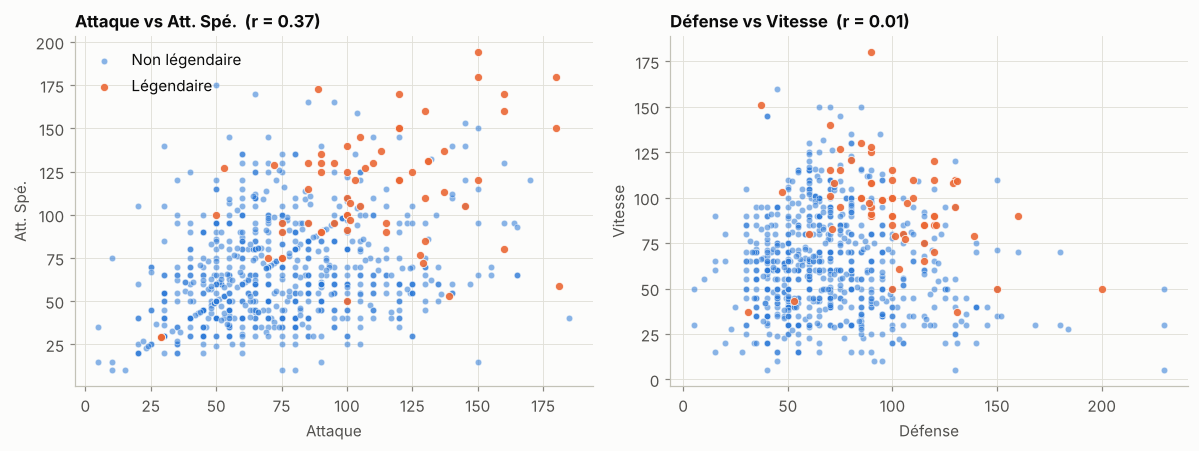

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
paires = [("attack", "sp_attack"), ("defense", "speed")]
for ax, (a, b) in zip(axes, paires):
    for k in (0, 1):
        sub = df[df[TARGET_LEGENDARY] == k]
        ax.scatter(sub[a], sub[b], s=18 if k == 0 else 28, color=LEG_PALETTE[k],
                   alpha=0.55 if k == 0 else 0.9, edgecolor="white", linewidth=0.5,
                   label=LEG_LABELS[k])
    r = df[[a, b]].corr().iloc[0, 1]
    ax.set(xlabel=STAT_LABELS[a], ylabel=STAT_LABELS[b],
           title=f"{STAT_LABELS[a]} vs {STAT_LABELS[b]}  (r = {r:.2f})")
axes[0].legend(loc="upper left")
fig.tight_layout()
save_fig(fig, "06_nuages_points")
plt.show()

**Lecture**

- **Toutes les corrélations sont positives** (de 0,01 à 0,53 avec Pearson). Un Pokémon fort dans une stat a tendance à l'être dans les autres. On peut y voir un **facteur général de « puissance »**, lié au stade d'évolution et au statut légendaire. Ce sera la première composante principale de l'ACP à l'étape 2.
- Les paires les plus corrélées suivent la logique du jeu : **Défense et Défense spéciale** (0,53), **Attaque spéciale et Défense spéciale** (0,51), **Attaque et Défense** (0,47).
- **Défense et Vitesse sont indépendantes** (r = 0,01). C'est le compromis classique entre un Pokémon lent et blindé et un Pokémon rapide et fragile. Cet axe devrait faire apparaître des groupes au clustering.
- Spearman donne des valeurs un peu plus élevées que Pearson (par exemple PV–Attaque : 0,56 contre 0,41). Les valeurs extrêmes, comme Leuphorie avec ses 255 PV mais 10 en Attaque, **affaiblissent** donc la corrélation linéaire.
- Aucune corrélation ne dépasse 0,6 : **aucune stat n'est redondante**, on garde les 6.

### 1.4 Répartition des types

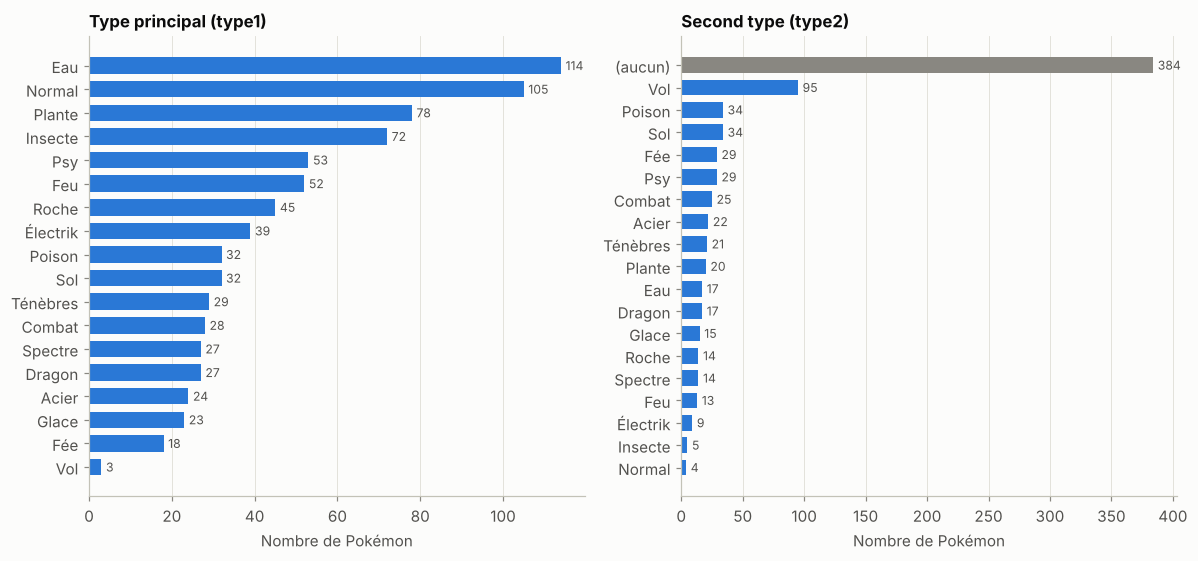

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
t1 = df["type1"].map(TYPE_FR).value_counts()
t2 = df["type2"].map(TYPE_FR).value_counts()
for ax, counts, titre in zip(axes, [t1, t2], ["Type principal (type1)", "Second type (type2)"]):
    counts = counts.sort_values()
    colors = [MUTED if i == TYPE_FR[NO_TYPE2] else COLOR_NON_LEG for i in counts.index]
    bars = ax.barh(counts.index, counts.values, color=colors, height=0.7)
    ax.bar_label(bars, padding=3, fontsize=8, color=INK_2)
    ax.set_title(titre)
    ax.set_xlabel("Nombre de Pokémon")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "07_repartition_types")
plt.show()

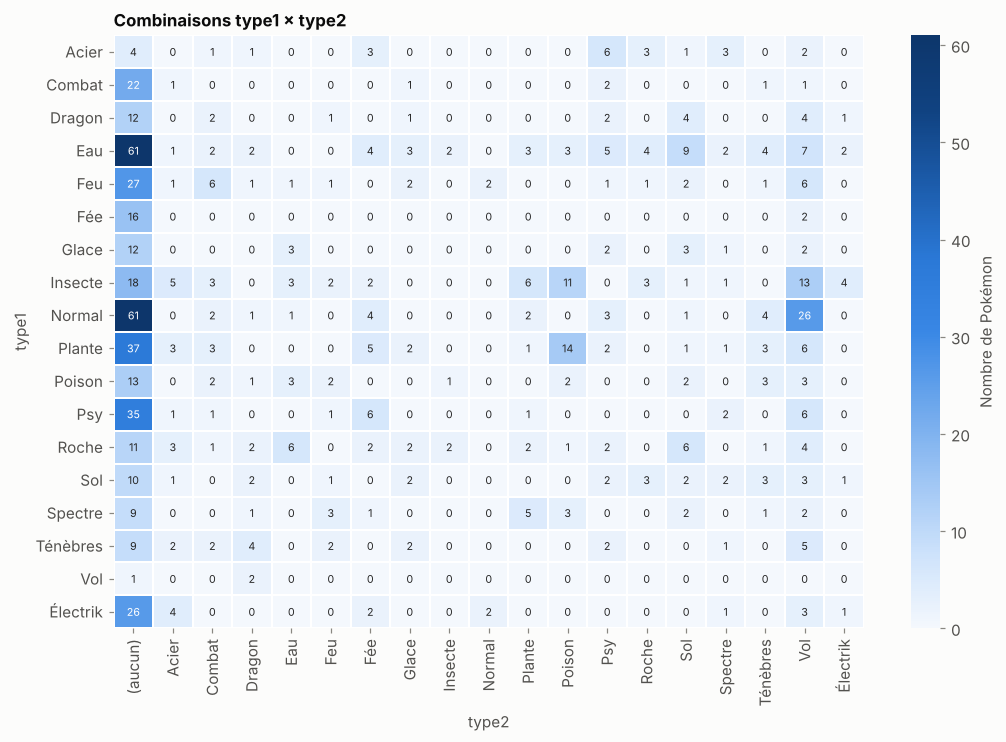

In [15]:
ct = pd.crosstab(df["type1"].map(TYPE_FR), df["type2"].map(TYPE_FR))
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(ct, annot=True, fmt="d", cmap=CMAP_SEQ, linewidths=1, linecolor="white",
            cbar_kws=dict(label="Nombre de Pokémon"), annot_kws=dict(fontsize=7), ax=ax)
ax.set(title="Combinaisons type1 × type2", xlabel="type2", ylabel="type1")
ax.grid(False)
save_fig(fig, "08_type1_x_type2")
plt.show()

**Lecture**

- Les classes de `type1` sont **très déséquilibrées** : Eau (114), Normal (105) et Plante (78) dominent, tandis que Fée (18) et surtout **Vol (3)** sont rares.
- **Vol est un cas particulier.** Seulement 3 Pokémon l'ont comme type principal, mais 95 l'ont comme second type (par exemple Normal/Vol pour les oiseaux du début de jeu). Avec 3 exemples, aucun modèle ne pourra apprendre ce type. De plus, une validation croisée stratifiée à 5 plis demande au moins 5 exemples par classe. **Nous réglerons ce point à l'étape 4.**
- 48 % des Pokémon n'ont pas de second type (`aucun`).
- Les combinaisons les plus fréquentes sont Normal/Vol, Plante/Poison et Insecte/Vol.

### 1.5 Profil statistique moyen par type

Pour chaque type, on calcule la moyenne de chaque stat, exprimée en **z-score** par rapport à l'ensemble des Pokémon. La valeur $+1$ signifie : un écart-type au-dessus de la moyenne générale. Ce tableau indique **à l'avance** quels types les stats pourront reconnaître.

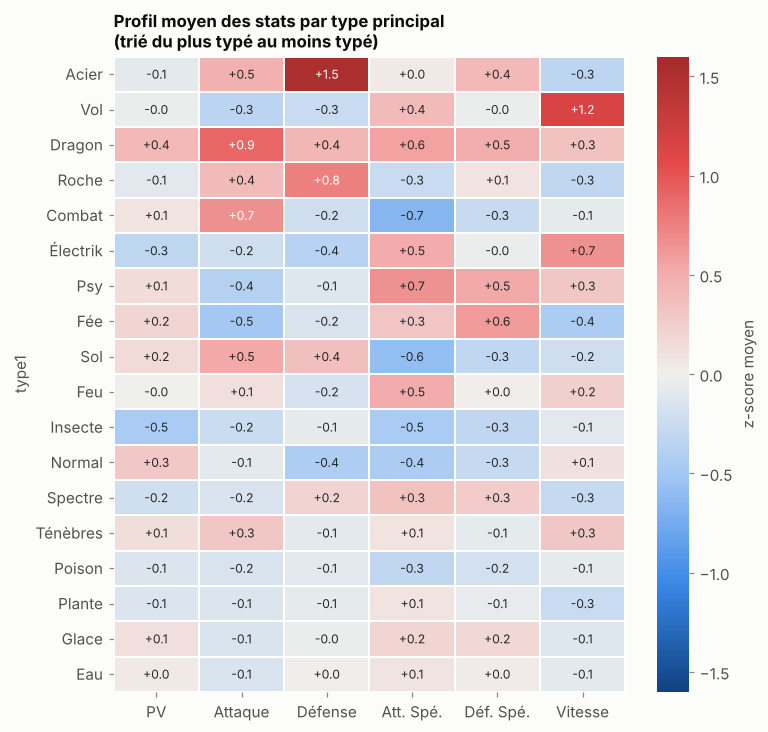

In [16]:
prof = df.groupby(df["type1"].map(TYPE_FR))[STATS].mean()
prof_z = (prof - df[STATS].mean()) / df[STATS].std()
prof_z = prof_z.loc[prof_z.abs().max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(7.5, 7.5))
sns.heatmap(prof_z, annot=True, fmt="+.1f", cmap=CMAP_DIV, vmin=-1.6, vmax=1.6, center=0,
            linewidths=1, linecolor="white", xticklabels=LABELS6,
            cbar_kws=dict(label="z-score moyen"), annot_kws=dict(fontsize=8), ax=ax)
ax.set(title="Profil moyen des stats par type principal\n(trié du plus typé au moins typé)",
       ylabel="type1", xlabel="")
ax.grid(False)
save_fig(fig, "09_profil_stats_par_type")
plt.show()

**Lecture : certains types ont une « signature » statistique, d'autres non.**

| Type | Signature | Pourquoi (logique du jeu) |
|---|---|---|
| Acier | Défense **+1,5** | carapaces métalliques (Steelix, Airmure…) |
| Vol | Vitesse **+1,2** | mais seulement 3 Pokémon, donc peu fiable |
| Roche | Défense +0,8, Vitesse −0,3 | lents et blindés |
| Dragon | tout positif, Attaque +0,9 | beaucoup de légendaires et de pseudo-légendaires |
| Combat | Attaque +0,7, Att. Spé. **−0,7** | attaquants physiques purs |
| Psy | Att. Spé. +0,7, Déf. Spé. +0,5, Attaque −0,4 | attaquants spéciaux |
| Électrik | Vitesse +0,7, Att. Spé. +0,5 | rapides et spéciaux |
| Fée | Déf. Spé. +0,6, Attaque −0,5 | défenseurs spéciaux |
| **Eau, Plante, Poison, Glace** | **tout proche de 0** | profils variés, sans signature |

**Conséquence pour l'étape 4 :** on peut s'attendre à reconnaître correctement l'Acier, la Roche, le Combat, le Psy et l'Électrik. **Eau** et **Normal**, pourtant les types les plus nombreux, n'ont pas de profil distinctif : ils seront confondus avec tous les autres. Le type d'un Pokémon est d'abord un choix **thématique** (son apparence, son élément), pas statistique. Il faut donc s'attendre à une précision modeste.

### 1.6 Les légendaires : un fort déséquilibre de classes

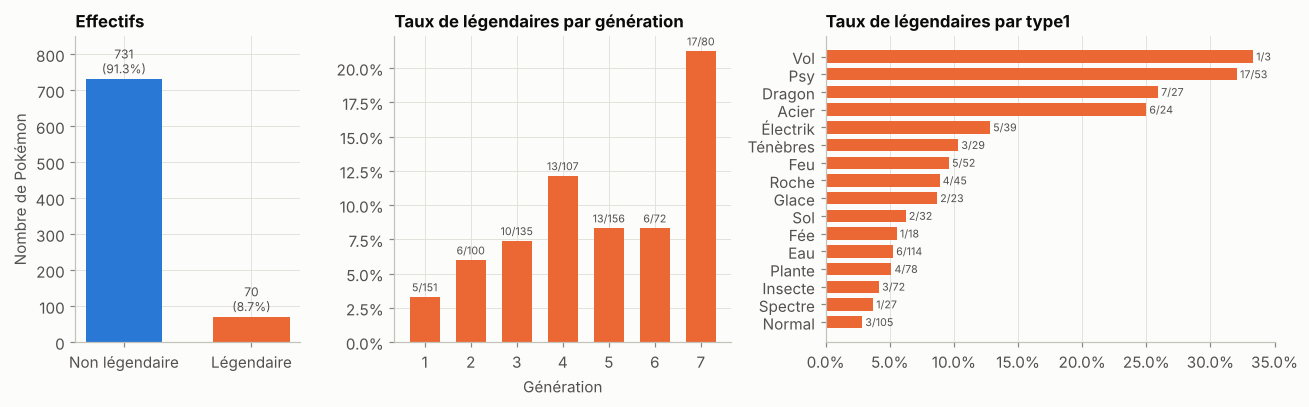

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[0.8, 1.2, 1.6]))

ax = axes[0]
cnt = df[TARGET_LEGENDARY].value_counts().sort_index()
bars = ax.bar([LEG_LABELS[k] for k in cnt.index], cnt.values,
              color=[LEG_PALETTE[k] for k in cnt.index], width=0.6)
ax.bar_label(bars, labels=[f"{v}\n({v / len(df):.1%})" for v in cnt.values], padding=2,
             color=INK_2, fontsize=8)
ax.set(title="Effectifs", ylabel="Nombre de Pokémon", ylim=(0, 850))

ax = axes[1]
g = df.groupby("generation")[TARGET_LEGENDARY].agg(["mean", "sum", "size"])
bars = ax.bar(g.index.astype(str), g["mean"], color=COLOR_LEG, width=0.65)
ax.bar_label(bars, labels=[f"{s}/{n}" for s, n in zip(g["sum"], g["size"])], padding=2,
             fontsize=7, color=INK_2)
ax.set(title="Taux de légendaires par génération", xlabel="Génération")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))

ax = axes[2]
t = df.groupby(df["type1"].map(TYPE_FR))[TARGET_LEGENDARY].agg(["mean", "sum", "size"]).sort_values("mean")
t = t[t["sum"] > 0]
bars = ax.barh(t.index, t["mean"], color=COLOR_LEG, height=0.7)
ax.bar_label(bars, labels=[f"{s}/{n}" for s, n in zip(t["sum"], t["size"])], padding=2,
             fontsize=7, color=INK_2)
ax.set(title="Taux de légendaires par type1")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "10_legendaires")
plt.show()

**Lecture**

- **70 légendaires sur 801, soit 8,7 %.** Un modèle « paresseux » qui répondrait toujours « non légendaire » obtiendrait **91,3 % d'accuracy** sans avoir rien appris. C'est pourquoi l'accuracy seule ne suffit pas pour évaluer le modèle. On utilisera à l'étape 3 :
  - le **rappel** : la part des légendaires retrouvés ;
  - la **précision** : la part des Pokémon prédits légendaires qui le sont vraiment ;
  - le **F1**, la **PR-AUC** et la matrice de confusion.
- Le taux de légendaires **augmente avec les générations** : 3 % en génération 1, 21 % en génération 7 (les Ultra-Chimères, Tokorico…). On n'utilise **pas** la génération comme variable, car elle n'est pas saisie dans l'appli. En revanche, cette dérive dans le temps sera une **limite** à mentionner dans le rapport.
- Les légendaires sont concentrés chez les **Psy** (17 sur 53), **Dragon** (7 sur 27) et **Acier** (6 sur 24). Le type et le statut légendaire sont donc liés, ce qu'on retrouvera au croisement avec les clusters.
- **Ce qu'on en tire pour la suite :**
  - **découpage stratifié**, pour garder 8,7 % de légendaires dans le train et dans le test (on obtient 56 légendaires sur 640 et 14 sur 161) ;
  - **validation croisée stratifiée** ;
  - pondération des classes (`class_weight="balanced"`) ou suréchantillonnage (SMOTE).

### 1.7 Taille et poids (variante à comparer)

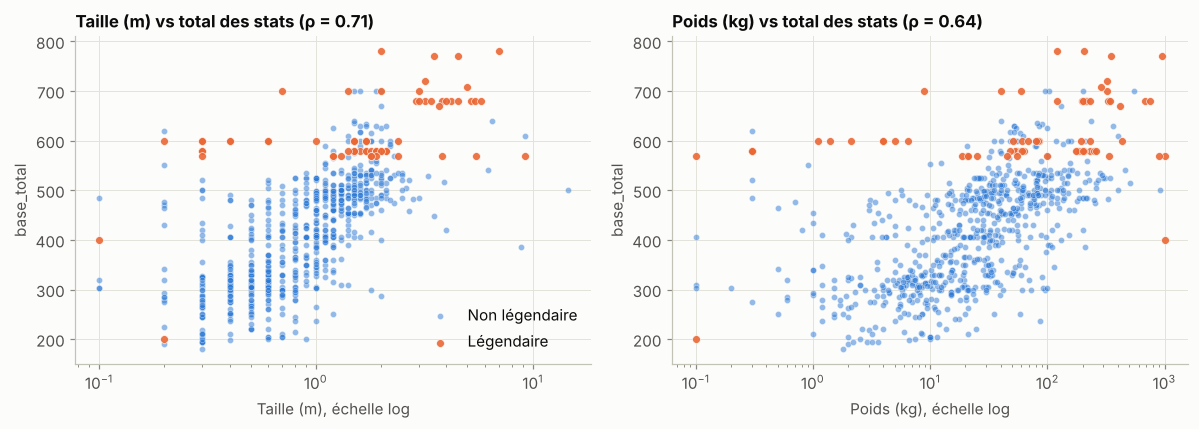

Asymétrie : {'height_m': 5.1, 'weight_kg': 4.9}


,height_m,weight_kg
is_legendary,,
Non légendaire,0.9,24.95
Légendaire,1.8,120.00


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, lab in zip(axes, PHYSICAL, ["Taille (m), échelle log", "Poids (kg), échelle log"]):
    for k in (0, 1):
        sub = df[df[TARGET_LEGENDARY] == k]
        ax.scatter(sub[col], sub["base_total"], s=16 if k == 0 else 26, color=LEG_PALETTE[k],
                   alpha=0.5 if k == 0 else 0.9, edgecolor="white", linewidth=0.4,
                   label=LEG_LABELS[k])
    ax.set_xscale("log")
    rho = df[[col, "base_total"]].corr(method="spearman").iloc[0, 1]
    ax.set(xlabel=lab, ylabel="base_total", title=f"{lab.split(',')[0]} vs total des stats (ρ = {rho:.2f})")
axes[0].legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "11_taille_poids")
plt.show()

print("Asymétrie :", df[PHYSICAL].skew().round(1).to_dict())
df.groupby(TARGET_LEGENDARY)[PHYSICAL].median().rename(index=LEG_LABELS)

**Lecture**

- La taille et le poids sont **extrêmement asymétriques** (asymétrie autour de 5) : le poids va de 0,1 kg à 999,9 kg. On les passera donc en **logarithme** $\log(1 + x)$ avant de les standardiser. Sans cela, quelques géants (Cosmovum et Bamboiselle à 999,9 kg, Groudon à 950 kg) écraseraient la distance.
- Les légendaires sont **plus grands** (1,8 m contre 0,9 m en médiane) et **plus lourds** (120 kg contre 25 kg). Ces deux variables sont aussi corrélées aux stats : avec le total, ρ = 0,71 pour la taille et 0,64 pour le poids. Elles apportent donc un peu d'information, mais en partie **redondante**. L'étape 3 mesurera si elles améliorent réellement la prédiction.

### 1.8 Synthèse de l'exploration

| Constat | Conséquence pour la modélisation |
|---|---|
| Stats sur des échelles différentes, distributions asymétriques | **Standardisation** (z-score) obligatoire pour K-means, k-NN, SVM et la régression logistique |
| Valeurs extrêmes réelles (Leuphorie, Caratroc) | On les **garde**. Les méthodes de rang (Spearman) et les arbres y sont robustes |
| Corrélations toutes positives (facteur de « puissance ») | La 1ʳᵉ composante de l'ACP = puissance globale. Le clustering séparera probablement les Pokémon faibles des forts, puis par profil |
| Défense et Vitesse indépendantes, Attaque et Att. Spé. peu corrélées | Axes physique/spécial et lent/rapide : base des **noms de clusters** |
| 8,7 % de légendaires | **Stratification**, métriques adaptées au déséquilibre, `class_weight` ou SMOTE |
| Chevauchement avec les pseudo-légendaires | Afficher une **probabilité** (bien calibrée) plutôt qu'un oui/non |
| 18 types déséquilibrés, Vol = 3 exemples | Traitement des types rares, F1 **macro**, top-3 accuracy |
| Eau et Normal sans signature statistique | Précision du type attendue modeste : analyser type par type |
| Taille et poids très asymétriques, 20 valeurs manquantes | `log1p` + imputation par la médiane **dans le pipeline** (variante) |
| Colonnes qui trichent (`capture_rate`, `base_egg_steps`, `against_*`…) | **Exclues** : seules les 6 stats servent d'entrée |

## 2. Clustering : quels grands profils de Pokémon ?

**Objectif :** regrouper les Pokémon qui ont des stats **semblables**, sans utiliser aucune étiquette (ni le statut légendaire, ni le type). C'est de l'apprentissage **non supervisé**. On regarde ensuite **après coup** si les groupes trouvés ont un lien avec les légendaires et les types.

**Données utilisées :** les 6 stats standardisées des **801 Pokémon**. Pour le clustering, il n'y a pas de découpage train/test : aucune cible n'est utilisée, donc rien ne peut fuiter vers une réponse. Le numéro de cluster n'est d'ailleurs **pas** réutilisé comme variable par les classifieurs des parties 3 et 4. L'appli appliquera le **même** scaler et le **même** modèle à n'importe quel Pokémon saisi.

### 2.1 Standardisation

$$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$

Après cette transformation, chaque stat $j$ a une moyenne de 0 et un écart-type de 1. Pourquoi c'est indispensable ici :

- K-means et la CAH de Ward mesurent des **distances euclidiennes** $\|\mathbf{z}_i - \mathbf{z}_k\|^2 = \sum_j (z_{ij} - z_{kj})^2$. Chaque stat y contribue en proportion de sa dispersion.
- Sans standardisation, l'Attaque spéciale (σ = 32) pèserait environ 1,4 fois plus que les PV (σ = 27) dans le carré de la distance, alors que rien ne justifie de lui donner plus d'importance.
- Avec la standardisation, **chaque stat compte autant**.

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import chi2_contingency
from src.clustering import name_clusters, cluster_info, cluster_profiles

scaler = StandardScaler()
Z = scaler.fit_transform(df[STATS])
print("moyennes :", Z.mean(axis=0).round(2))
print("écarts-types :", Z.std(axis=0).round(2))

moyennes : [-0.  0. -0. -0.  0.  0.]
écarts-types : [1. 1. 1. 1. 1. 1.]


### 2.2 K-means : principe et choix de k

**Algorithme (Lloyd)**

1. On place $k$ centres $\boldsymbol{\mu}_1, \dots, \boldsymbol{\mu}_k$. L'initialisation *k-means++* écarte les centres les uns des autres.
2. **Affectation :** chaque Pokémon rejoint le centre le plus proche.
3. **Mise à jour :** chaque centre devient la moyenne des Pokémon de son groupe.
4. On répète les étapes 2 et 3 jusqu'à ce que plus rien ne bouge.

Ces étapes font baisser à chaque tour l'**inertie**, c'est-à-dire la somme des carrés des distances intra-cluster :

$$W(k) = \sum_{c=1}^{k} \sum_{i \in C_c} \|\mathbf{z}_i - \boldsymbol{\mu}_c\|^2$$

L'algorithme converge vers un **minimum local**, qui dépend de l'initialisation. On le relance donc 20 fois (`n_init=20`) et on garde la meilleure solution.

**Deux critères pour choisir $k$**

- **Méthode du coude :** $W(k)$ diminue toujours quand $k$ augmente. Avec $k = n$, on aurait $W = 0$. On cherche donc le $k$ au-delà duquel le gain devient faible : le « coude » de la courbe.
- **Score silhouette :** pour un Pokémon $i$, on note $a(i)$ sa distance moyenne aux membres de **son** cluster (cohésion) et $b(i)$ sa distance moyenne aux membres du cluster **voisin le plus proche** (séparation). On calcule alors

$$s(i) = \frac{b(i) - a(i)}{\max\big(a(i),\, b(i)\big)} \in [-1, 1]$$

  - $s(i)$ proche de 1 : le Pokémon est bien placé ;
  - $s(i)$ proche de 0 : il est à la frontière entre deux groupes ;
  - $s(i)$ négatif : il serait mieux dans le groupe voisin.

  Le score global est la moyenne des $s(i)$.

Deux indices complètent l'analyse :
- **Davies-Bouldin** : plus il est bas, mieux c'est ;
- **Calinski-Harabasz** : plus il est haut, mieux c'est.

In [20]:
K_RANGE = range(2, 11)
rows = []
for k in K_RANGE:
    km_k = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z)
    ward_k = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Z)
    rows.append({"k": k, "inertie": km_k.inertia_,
                 "silhouette K-means": silhouette_score(Z, km_k.labels_),
                 "silhouette CAH Ward": silhouette_score(Z, ward_k),
                 "Davies-Bouldin": davies_bouldin_score(Z, km_k.labels_),
                 "Calinski-Harabasz": calinski_harabasz_score(Z, km_k.labels_)})
scores_k = pd.DataFrame(rows).set_index("k")
scores_k.style.format("{:.3f}").format("{:.0f}", subset=["inertie", "Calinski-Harabasz"]) \
    .highlight_max(subset=["silhouette K-means", "silhouette CAH Ward", "Calinski-Harabasz"], color="#cde2fb") \
    .highlight_min(subset=["Davies-Bouldin"], color="#cde2fb")

,inertie,silhouette K-means,silhouette CAH Ward,Davies-Bouldin,Calinski-Harabasz
k,,,,,
2,3285,0.290,0.270,1.313,370
3,2866,0.258,0.255,1.743,270
4,2575,0.230,0.220,1.558,230
5,2341,0.234,0.217,1.479,210
6,2193,0.225,0.117,1.448,189
7,2032,0.237,0.105,1.360,181
8,1921,0.172,0.115,1.516,170
9,1842,0.158,0.121,1.559,159
10,1768,0.156,0.124,1.456,151


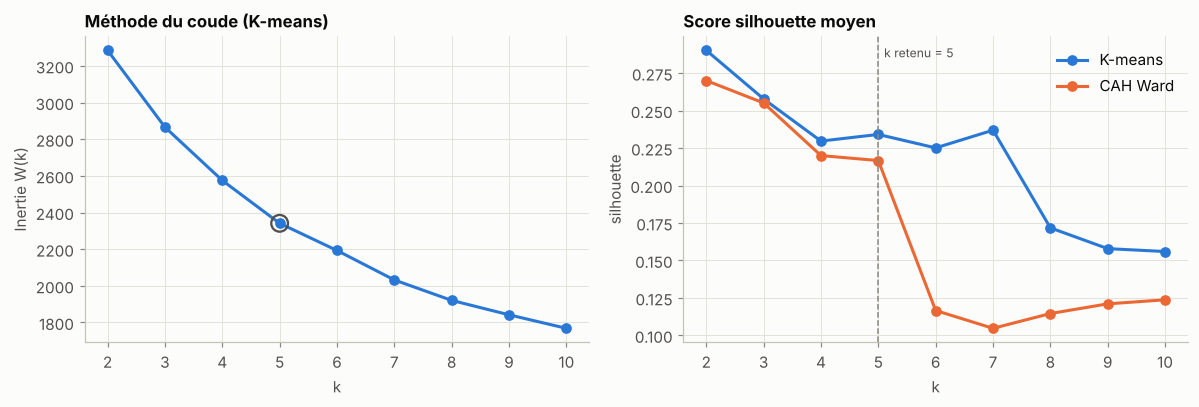

In [21]:
K_CHOISI = 5
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.plot(scores_k.index, scores_k["inertie"], marker="o", ms=6, color=SERIES[0])
ax.scatter([K_CHOISI], [scores_k.loc[K_CHOISI, "inertie"]], s=120, facecolor="none",
           edgecolor=INK_2, lw=1.5, zorder=3)
ax.set(title="Méthode du coude (K-means)", xlabel="k", ylabel="Inertie W(k)")
ax = axes[1]
for col, color in [("silhouette K-means", SERIES[0]), ("silhouette CAH Ward", SERIES[1])]:
    ax.plot(scores_k.index, scores_k[col], marker="o", ms=6, color=color,
            label=col.replace("silhouette ", ""))
ax.axvline(K_CHOISI, color=MUTED, ls="--", lw=1)
ax.text(K_CHOISI + 0.1, ax.get_ylim()[1] * 0.98, f"k retenu = {K_CHOISI}", color=INK_2,
        fontsize=8, va="top")
ax.set(title="Score silhouette moyen", xlabel="k", ylabel="silhouette")
ax.legend()
for a in axes:
    a.set_xticks(list(K_RANGE))
fig.tight_layout()
save_fig(fig, "12_coude_silhouette")
plt.show()

**Lecture et choix de k = 5**

- **Le coude n'est pas net.** L'inertie baisse régulièrement, avec un léger ralentissement vers k = 4 ou 5. C'est fréquent quand les données forment un nuage continu plutôt que des amas bien séparés.
- **La silhouette est maximale pour k = 2** (0,29). Mais cette partition triviale coupe seulement les Pokémon en « faibles » et « forts », ce qui revient à la première composante de l'ACP et n'apprend rien de plus que `base_total`.
- **Au-delà de k = 2**, la silhouette forme un plateau entre 0,23 et 0,26 jusqu'à k = 7. Elle remonte légèrement entre k = 4 et k = 5, et le Davies-Bouldin diminue entre k = 4 et k = 5. Pour la CAH de Ward, la silhouette s'effondre à partir de k = 6.
- **On retient k = 5**, un compromis entre trois critères :
  1. des indices de qualité comparables aux meilleurs k > 2 ;
  2. **l'interprétabilité** : 5 profils de jeu clairs et nommables (voir 2.6) ;
  3. **la stabilité** (voir 2.3).

**Point à assumer à l'oral :** avec des silhouettes autour de 0,23, la structure en groupes est **faible**. Les Pokémon ne forment pas des familles isolées, mais un continuum. Le clustering sert donc à **résumer** ce continuum en grands profils, pas à découvrir des espèces cachées.

### 2.3 Modèle K-means retenu, silhouette détaillée et stabilité

In [22]:
kmeans = KMeans(n_clusters=K_CHOISI, n_init=20, random_state=RANDOM_STATE).fit(Z)
cluster_keys = name_clusters(kmeans.cluster_centers_)           # numéro -> clé du profil
CL = {i: cluster_info(k) for i, k in cluster_keys.items()}       # numéro -> nom, couleur…
df["cluster"] = kmeans.labels_
df["cluster_nom"] = df["cluster"].map(lambda c: CL[c]["name"])
ORDRE = sorted(CL, key=lambda c: Z[kmeans.labels_ == c].mean())  # du plus faible au plus fort
COL = {c: CL[c]["color"] for c in CL}

sil = silhouette_samples(Z, kmeans.labels_)
pd.DataFrame({"nom": [CL[c]["name"] for c in ORDRE],
              "effectif": [int((kmeans.labels_ == c).sum()) for c in ORDRE],
              "silhouette moyenne": [sil[kmeans.labels_ == c].mean() for c in ORDRE],
              "% de s(i) < 0": [(sil[kmeans.labels_ == c] < 0).mean() * 100 for c in ORDRE]},
             index=pd.Index(ORDRE, name="cluster")).round(3)

,nom,effectif,silhouette moyenne,% de s(i) < 0
cluster,,,,
1,Pokémon faibles / non évolués,297,0.36,0.00
0,Attaquants rapides,188,0.22,3.19
3,Tanks défensifs,93,0.13,12.90
2,Colosses à PV,100,0.12,14.00
4,Puissants / quasi-légendaires,123,0.12,17.89


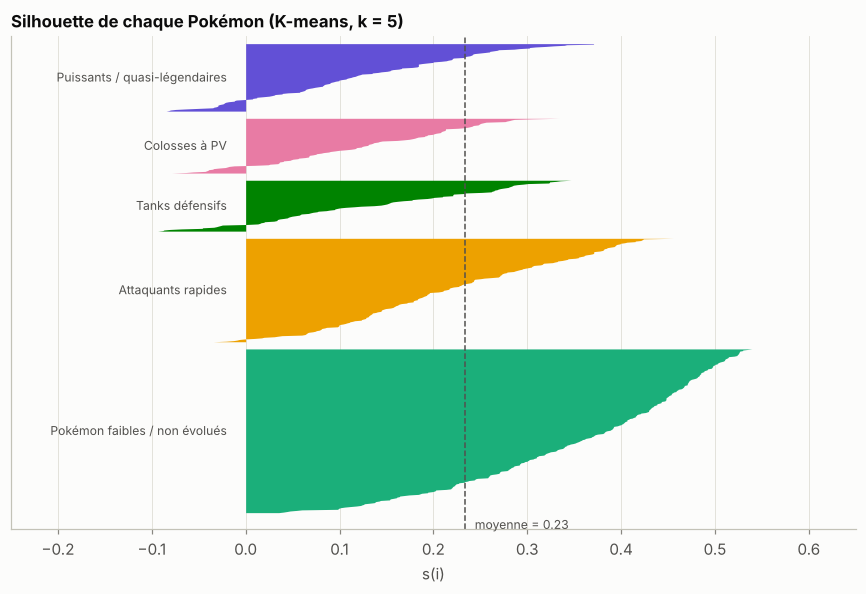

In [23]:
fig, ax = plt.subplots(figsize=(8, 5.5))
y0 = 0
for c in ORDRE:
    s = np.sort(sil[kmeans.labels_ == c])
    ax.fill_betweenx(np.arange(y0, y0 + len(s)), 0, s, color=COL[c], lw=0)
    ax.text(-0.02, y0 + len(s) / 2, CL[c]["name"], ha="right", va="center", fontsize=8,
            color=INK_2)
    y0 += len(s) + 12
ax.axvline(sil.mean(), color=INK_2, ls="--", lw=1)
ax.text(sil.mean() + 0.01, -8, f"moyenne = {sil.mean():.2f}", fontsize=8, color=INK_2, va="top")
ax.set(title=f"Silhouette de chaque Pokémon (K-means, k = {K_CHOISI})", xlabel="s(i)",
       yticks=[], xlim=(-0.25, 0.65), ylim=(-30, y0))
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "13_silhouette_k5")
plt.show()

In [24]:
# Stabilité 1 : sensibilité à l'initialisation (une seule initialisation par graine)
ari_init = [adjusted_rand_score(kmeans.labels_,
                                KMeans(K_CHOISI, n_init=1, random_state=s).fit_predict(Z))
            for s in range(20)]
# Stabilité 2 : bootstrap. On réentraîne sur 30 rééchantillonnages, puis on
# compare l'affectation de TOUS les Pokémon à la partition de référence.
rng = np.random.default_rng(RANDOM_STATE)
ari_boot = []
for _ in range(30):
    idx = rng.choice(len(Z), size=len(Z), replace=True)
    km_b = KMeans(K_CHOISI, n_init=10, random_state=RANDOM_STATE).fit(Z[idx])
    ari_boot.append(adjusted_rand_score(kmeans.labels_, km_b.predict(Z)))
print(f"ARI, 1 seule initialisation : min {min(ari_init):.2f}, médiane {np.median(ari_init):.2f}")
print(f"ARI bootstrap (n_init=10)    : {np.mean(ari_boot):.2f} ± {np.std(ari_boot):.2f}")

ARI, 1 seule initialisation : min 0.52, médiane 0.83
ARI bootstrap (n_init=10)    : 0.81 ± 0.05


**Lecture**

- **La silhouette varie selon les groupes.**
  - Le groupe des « faibles » est le plus net (environ 0,36) : on l'identifie sans ambiguïté.
  - Les trois groupes spécialisés et les « puissants » sont proches de 0,12–0,22. Plusieurs de leurs membres sont à la frontière, ce qui confirme le continuum vu en 2.2.
- **L'indice de Rand ajusté (ARI)** compare deux partitions. Il vaut 1 si elles sont identiques et environ 0 si leur accord est dû au hasard. Il ne dépend pas des numéros donnés aux clusters.
  - **Avec une seule initialisation**, l'ARI descend parfois à environ 0,5 : K-means tombe alors dans un minimum local différent. C'est ce qui justifie `n_init=20`.
  - **Sur 30 rééchantillonnages bootstrap**, l'ARI moyen est d'environ 0,8. Les groupes sont donc **raisonnablement stables** : ils ne sont pas un artefact de l'échantillon.

### 2.4 Deuxième méthode : classification ascendante hiérarchique (CAH, Ward)

**Principe**

1. Au départ, chaque Pokémon forme son propre groupe.
2. À chaque étape, on fusionne les **deux groupes** dont la fusion fait **le moins augmenter l'inertie intra-classe**. C'est le critère de Ward : $\Delta(A, B) = \frac{|A||B|}{|A| + |B|} \|\boldsymbol{\mu}_A - \boldsymbol{\mu}_B\|^2$.

On obtient un arbre de fusions, le **dendrogramme**. Le couper à une hauteur donnée fournit $k$ groupes. Ward minimise le même critère que K-means, mais de manière **gloutonne et déterministe** : il n'y a pas d'initialisation aléatoire.

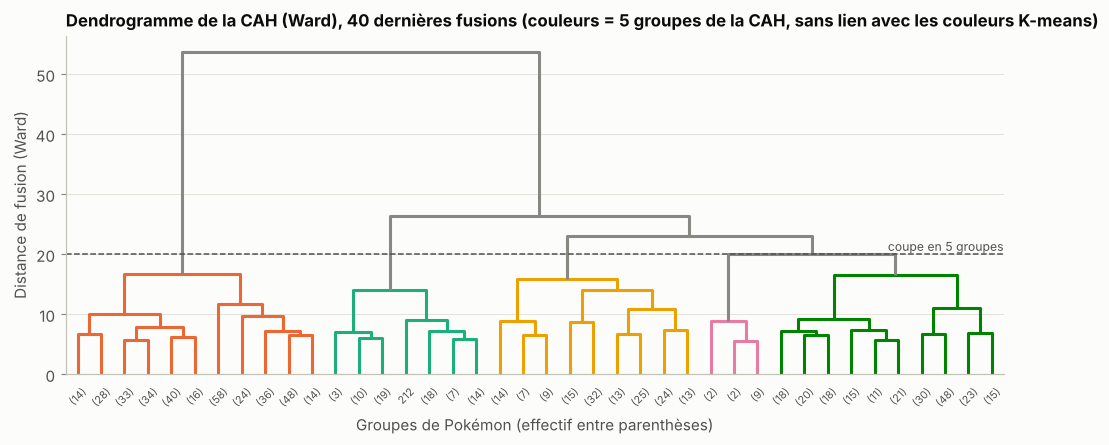

Silhouette CAH Ward (k=5) : 0.217  |  ARI avec K-means : 0.58


In [25]:
Lk = linkage(Z, method="ward")
fig, ax = plt.subplots(figsize=(11, 4))
dendrogram(Lk, truncate_mode="lastp", p=40, color_threshold=Lk[-(K_CHOISI - 1), 2],
           above_threshold_color=MUTED, leaf_font_size=7, ax=ax)
ax.axhline(Lk[-(K_CHOISI - 1), 2], color=INK_2, ls="--", lw=1)
ax.text(ax.get_xlim()[1], Lk[-(K_CHOISI - 1), 2], f" coupe en {K_CHOISI} groupes", va="bottom",
        ha="right", fontsize=8, color=INK_2)
ax.set(title="Dendrogramme de la CAH (Ward), 40 dernières fusions (couleurs = 5 groupes de la CAH, sans lien avec les couleurs K-means)",
       ylabel="Distance de fusion (Ward)", xlabel="Groupes de Pokémon (effectif entre parenthèses)")
ax.grid(axis="x", visible=False)
save_fig(fig, "14_dendrogramme_ward")
plt.show()

ward = AgglomerativeClustering(n_clusters=K_CHOISI, linkage="ward").fit_predict(Z)
print(f"Silhouette CAH Ward (k={K_CHOISI}) : {silhouette_score(Z, ward):.3f}"
      f"  |  ARI avec K-means : {adjusted_rand_score(kmeans.labels_, ward):.2f}")

### 2.5 Troisième méthode : mélange de gaussiennes (GMM)

**Principe**

K-means suppose implicitement des groupes **sphériques** de même taille. Le GMM, lui, modélise la densité des données comme une somme pondérée de $k$ lois normales multivariées :

$$p(\mathbf{z}) = \sum_{c=1}^{k} \pi_c \, \mathcal{N}(\mathbf{z} \mid \boldsymbol{\mu}_c, \boldsymbol{\Sigma}_c)$$

Les paramètres sont estimés par l'algorithme **EM** (espérance-maximisation), qui alterne deux étapes :
- **étape E :** calcul de la probabilité d'appartenance de chaque Pokémon à chaque composante ;
- **étape M :** ré-estimation de $\pi_c$, $\boldsymbol{\mu}_c$ et $\boldsymbol{\Sigma}_c$.

Contrairement à K-means, l'affectation est **souple** : chaque Pokémon reçoit une probabilité pour chaque groupe.

**Choix du modèle par le critère BIC :** $\text{BIC} = -2 \ln \hat{L} + p \ln n$, où $p$ est le nombre de paramètres et $n$ le nombre de Pokémon. Le BIC récompense la vraisemblance mais pénalise la complexité, et on cherche le BIC le plus **bas**. On teste plusieurs formes de covariance :
- `full` : ellipsoïdes quelconques ;
- `tied` : même forme pour toutes les composantes ;
- `diag` : axes alignés sur les stats ;
- `spherical` : boules.

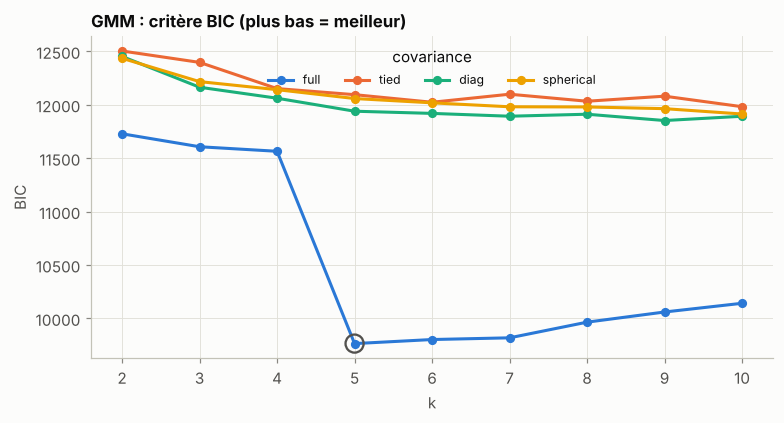

Meilleur BIC : covariance = full, k = 5


GMM full k=5     : silhouette -0.005, ARI avec K-means 0.12
GMM spherical k=5 : silhouette 0.200, ARI avec K-means 0.67


In [26]:
bic_rows = []
for cov in ["full", "tied", "diag", "spherical"]:
    for k in K_RANGE:
        g = GaussianMixture(k, covariance_type=cov, n_init=5, random_state=RANDOM_STATE).fit(Z)
        lab = g.predict(Z)
        bic_rows.append({"covariance": cov, "k": k, "BIC": g.bic(Z),
                         "silhouette": silhouette_score(Z, lab) if len(set(lab)) > 1 else np.nan})
bic = pd.DataFrame(bic_rows)

fig, ax = plt.subplots(figsize=(8, 3.8))
for (cov, sub), color in zip(bic.groupby("covariance", sort=False), SERIES):
    ax.plot(sub["k"], sub["BIC"], marker="o", ms=5, color=color, label=cov)
best = bic.loc[bic["BIC"].idxmin()]
ax.scatter([best["k"]], [best["BIC"]], s=140, facecolor="none", edgecolor=INK_2, lw=1.5, zorder=3)
ax.set(title="GMM : critère BIC (plus bas = meilleur)", xlabel="k", ylabel="BIC")
ax.set_xticks(list(K_RANGE))
ax.legend(title="covariance", ncol=4, loc="upper center", fontsize=8)
save_fig(fig, "15_gmm_bic")
plt.show()
print(f"Meilleur BIC : covariance = {best['covariance']}, k = {int(best['k'])}")

gmm = GaussianMixture(int(best["k"]), covariance_type=best["covariance"], n_init=5,
                      random_state=RANDOM_STATE).fit(Z)
gmm_lab = gmm.predict(Z)
gmm_sph = GaussianMixture(K_CHOISI, covariance_type="spherical", n_init=5,
                          random_state=RANDOM_STATE).fit_predict(Z)
print(f"GMM full k={int(best['k'])}     : silhouette {silhouette_score(Z, gmm_lab):.3f}, "
      f"ARI avec K-means {adjusted_rand_score(kmeans.labels_, gmm_lab):.2f}")
print(f"GMM spherical k={K_CHOISI} : silhouette {silhouette_score(Z, gmm_sph):.3f}, "
      f"ARI avec K-means {adjusted_rand_score(kmeans.labels_, gmm_sph):.2f}")

In [27]:
# Que trouve le GMM « full » ? Profil moyen de ses composantes
g_prof = df.assign(g=gmm_lab).groupby("g").agg(effectif=("name", "size"),
                                                base_total=("base_total", "mean"),
                                                pct_leg=(TARGET_LEGENDARY, "mean"))
g_prof["dispersion (trace Σ)"] = [np.trace(c) for c in gmm.covariances_]
g_prof["exemples"] = [", ".join(df.loc[gmm_lab == g, "name"].head(5)) for g in g_prof.index]
g_prof.round(2)

,effectif,base_total,pct_leg,dispersion (trace Σ),exemples
g,,,,,
0,48,539.60,0.33,9.79,"Charizard, Jigglypuff, Wigglytuff, Chansey, Mr..."
1,253,415.45,0.09,4.53,"Wartortle, Pidgeot, Rattata, Nidoran♂, Paras"
2,156,336.37,0.01,3.16,"Bulbasaur, Squirtle, Caterpie, Metapod, Weedle"
3,214,434.62,0.06,4.02,"Ivysaur, Charmander, Charmeleon, Butterfree, P..."
4,130,512.62,0.13,6.85,"Venusaur, Blastoise, Beedrill, Tentacool, Tent..."


**Lecture et comparaison des méthodes**

- **La CAH de Ward** donne une partition assez proche de K-means (ARI d'environ 0,6) et une silhouette légèrement inférieure. C'est logique : les deux méthodes minimisent l'inertie, l'une de façon exacte et itérative, l'autre de façon gloutonne.
- **Le meilleur BIC du GMM correspond aussi à k = 5**, avec une covariance `full`. C'est une confirmation indépendante du nombre de groupes, mais **les groupes trouvés sont différents** : ARI d'environ 0,1 avec K-means et silhouette proche de 0.
  - Avec des covariances libres, le GMM modélise la **densité**. Il découpe surtout le nuage en **couches de puissance** qui se chevauchent : le `base_total` moyen va d'environ 340 à environ 540 selon la composante. Il ajoute une composante **très dispersée** (trace de Σ ≈ 9,8, contre 3 à 7 pour les autres) qui récupère les profils extrêmes comme Leuphorie, Rondoudou ou Dracaufeu méga. Voir la colonne « dispersion ».
  - Ces composantes se chevauchent. La silhouette, qui suppose des groupes compacts et séparés, les juge donc mal.
  - Le GMM `spherical` se rapproche de K-means (ARI d'environ 0,7). C'est attendu : K-means est la limite d'un GMM sphérique à variance commune qui tend vers 0.
- **Choix : K-means avec k = 5**, pour quatre raisons :
  1. la meilleure silhouette parmi les méthodes testées à k = 5 ;
  2. une bonne stabilité au bootstrap ;
  3. des groupes **compacts et interprétables** ;
  4. une prédiction **triviale** pour l'appli : un nouveau Pokémon rejoint le centre le plus proche.

  Le GMM `full` serait plus adapté pour **détecter des profils atypiques** (faible densité), ce qui peut être une piste d'amélioration.

### 2.6 Visualisation en 2D par ACP

**Principe de l'ACP**

L'analyse en composantes principales cherche les directions orthogonales qui conservent le **plus de variance**. Ce sont les vecteurs propres $\mathbf{u}_1, \mathbf{u}_2, \dots$ de la matrice de covariance des données standardisées, c'est-à-dire de la **matrice de corrélation**. La valeur propre $\lambda_j$ associée au vecteur $\mathbf{u}_j$ donne la variance expliquée par cette composante.

On projette chaque Pokémon sur les deux premières composantes pour le dessiner en 2D.

**Attention :** l'ACP sert **uniquement à visualiser**. K-means a été appliqué sur les **6 dimensions**, et non sur la projection.

In [28]:
pca = PCA(random_state=RANDOM_STATE).fit(Z)
P = pca.transform(Z)
ev = pca.explained_variance_ratio_
loadings = pd.DataFrame(pca.components_[:3].T, index=LABELS6, columns=["CP1", "CP2", "CP3"])
display(pd.DataFrame({"variance expliquée": ev, "cumulée": ev.cumsum()},
                     index=[f"CP{i+1}" for i in range(6)]).T.round(3))
loadings.round(2)

,CP1,CP2,CP3,CP4,CP5,CP6
variance expliquée,0.45,0.18,0.13,0.12,0.07,0.04
cumulée,0.45,0.63,0.76,0.88,0.96,1.00


,CP1,CP2,CP3
PV,0.39,-0.06,0.35
Attaque,0.44,-0.01,0.65
Défense,0.39,-0.60,0.00
Att. Spé.,0.45,0.30,-0.35
Déf. Spé.,0.45,-0.22,-0.58
Vitesse,0.31,0.71,0.01


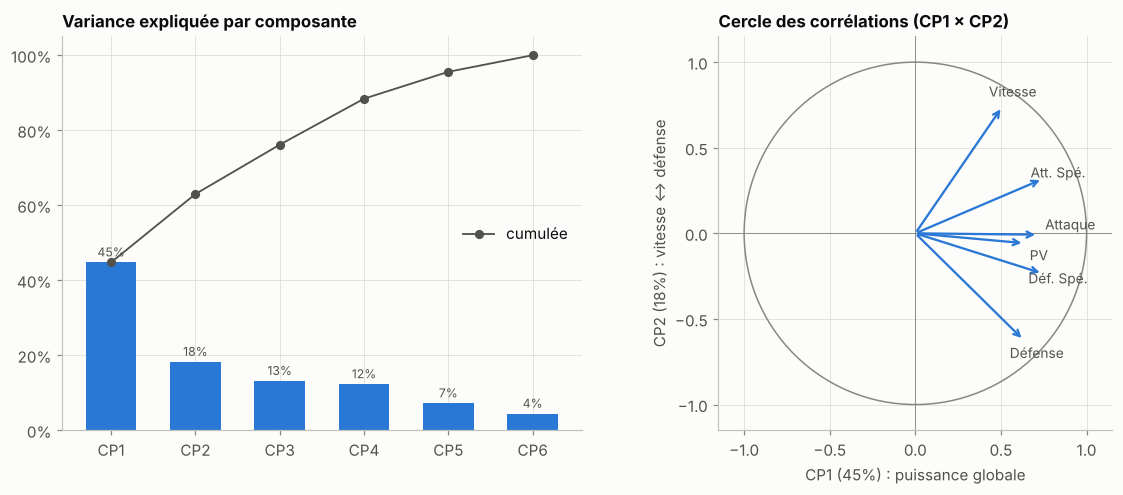

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw=dict(width_ratios=[1, 1.05]))
ax = axes[0]
bars = ax.bar([f"CP{i+1}" for i in range(6)], ev, color=SERIES[0], width=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in ev], padding=2, fontsize=8, color=INK_2)
ax.plot(range(6), ev.cumsum(), marker="o", ms=5, color=INK_2, lw=1.2, label="cumulée")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set(title="Variance expliquée par composante", ylim=(0, 1.05))
ax.legend(loc="center right")

ax = axes[1]
# Cercle des corrélations : corrélation entre chaque stat et CP1 / CP2
corr = pca.components_[:2].T * np.sqrt(pca.explained_variance_[:2])
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color=MUTED, lw=1))
# positions manuelles pour PV et Attaque, dont les flèches sont presque superposées
place = {"Attaque": dict(dx=0.04, dy=0.06, ha="left"), "PV": dict(dx=0.03, dy=-0.07, ha="left")}
for (x, y), lab in zip(corr, LABELS6):
    ax.annotate("", xy=(x, y), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color=SERIES[0], lw=1.5))
    if lab in place:
        q = place[lab]
        ax.text(x + q["dx"], y + q["dy"], lab, ha=q["ha"], va="center", fontsize=9, color=INK_2)
    else:
        ax.text(x * 1.12, y * 1.12, lab, ha="center", va="center", fontsize=9, color=INK_2)
ax.axhline(0, color=MUTED, lw=0.6); ax.axvline(0, color=MUTED, lw=0.6)
ax.set(xlim=(-1.15, 1.15), ylim=(-1.15, 1.15), aspect="equal",
       title="Cercle des corrélations (CP1 × CP2)",
       xlabel=f"CP1 ({ev[0]:.0%}) : puissance globale",
       ylabel=f"CP2 ({ev[1]:.0%}) : vitesse ↔ défense")
fig.tight_layout()
save_fig(fig, "16_acp_variance_cercle")
plt.show()

**Lecture des composantes**

- **CP1 (45 % de la variance) = puissance globale.** Toutes les stats y contribuent avec un poids proche de 0,4. Projeter un Pokémon sur CP1 revient presque à calculer son total de stats : c'est le facteur général repéré dans la matrice de corrélation (1.3).
- **CP2 (18 %) = Vitesse contre Défense.** La Vitesse a un poids de +0,71, la Défense de −0,60. Cet axe oppose les Pokémon **rapides et fragiles** aux Pokémon **lents et blindés**.
- **CP3 (13 %) = physique contre spécial.** L'Attaque (+0,65) s'oppose à la Défense spéciale (−0,58) et à l'Attaque spéciale (−0,35).
- Le plan CP1 × CP2 ne conserve que **63 %** de l'information. Des groupes qui se chevauchent sur la figure peuvent donc être séparés dans les dimensions 3 à 6.

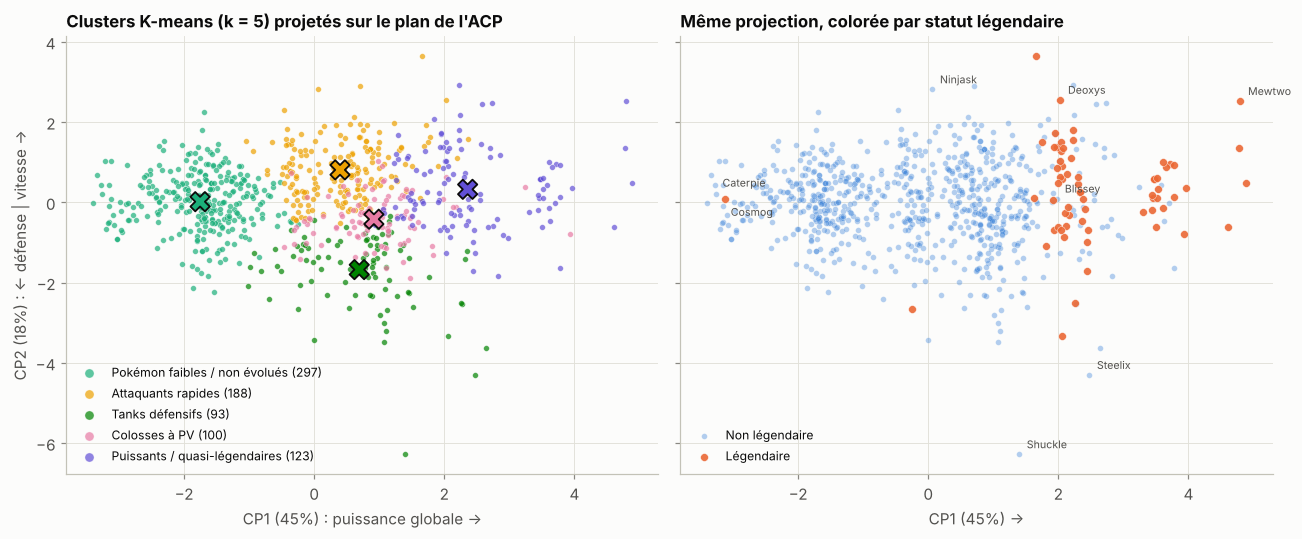

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
ax = axes[0]
for c in ORDRE:
    m = kmeans.labels_ == c
    ax.scatter(P[m, 0], P[m, 1], s=14, color=COL[c], alpha=0.7, edgecolor="white", lw=0.3,
               label=f"{CL[c]['name']} ({m.sum()})")
cent = pca.transform(kmeans.cluster_centers_)
ax.scatter(cent[:, 0], cent[:, 1], s=160, marker="X", color=[COL[c] for c in range(K_CHOISI)],
           edgecolor="#0b0b0b", lw=1.2, zorder=4)
ax.set(title="Clusters K-means (k = 5) projetés sur le plan de l'ACP",
       xlabel=f"CP1 ({ev[0]:.0%}) : puissance globale →", ylabel=f"CP2 ({ev[1]:.0%}) : ← défense | vitesse →")
ax.legend(fontsize=8, loc="lower left", markerscale=1.6)

ax = axes[1]
for k in (0, 1):
    m = df[TARGET_LEGENDARY].values == k
    ax.scatter(P[m, 0], P[m, 1], s=14 if k == 0 else 26, color=LEG_PALETTE[k],
               alpha=0.35 if k == 0 else 0.9, edgecolor="white", lw=0.3, label=LEG_LABELS[k])
decal = {"Cosmog": (4, -11), "Caterpie": (4, 5)}
for nom in ["Blissey", "Shuckle", "Ninjask", "Mewtwo", "Caterpie", "Cosmog", "Deoxys", "Steelix"]:
    i = df.index[df["name"] == nom][0]
    ax.annotate(nom, P[i, :2], xytext=decal.get(nom, (5, 4)), textcoords="offset points",
                fontsize=7, color=INK_2)
ax.set(title="Même projection, colorée par statut légendaire", xlabel=f"CP1 ({ev[0]:.0%}) →")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
save_fig(fig, "17_acp_clusters")
plt.show()

**Lecture**

- **Le long de CP1**, on voit de gauche à droite : les « faibles », puis les trois profils spécialisés, puis les « puissants ». Les **légendaires** (en orange) se concentrent tout à droite.
- **CP2 sépare les profils spécialisés :** les « attaquants rapides » en haut, les « tanks défensifs » en bas. Les « colosses à PV » sont au milieu : leur particularité, les PV, est surtout portée par d'autres composantes.
- **Les cas extrêmes sont faciles à repérer :**
  - Caratroc (Shuckle) : défense maximale, en bas ;
  - Ninjask : très rapide, en haut ;
  - Leuphorie (Blissey) : à part, avec ses 255 PV ;
  - Cosmog : un légendaire perdu chez les faibles.

### 2.7 Interprétation des clusters : profils moyens et noms

In [31]:
prof = cluster_profiles(df, kmeans.labels_).loc[ORDRE]
prof.insert(0, "nom", [CL[c]["name"] for c in ORDRE])
prof.rename(columns=STAT_LABELS).round(1)

,nom,PV,Attaque,Défense,Att. Spé.,Déf. Spé.,Vitesse,base_total,effectif,% légendaires
cluster,,,,,,,,,,
1,Pokémon faibles / non évolués,50.1,53.9,50.9,47.9,48.5,49.3,300.7,297,0.3
0,Attaquants rapides,67.8,84.5,68.0,77.4,71.6,93.3,462.6,188,2.7
3,Tanks défensifs,65.4,87.9,122.5,63.9,89.9,46.0,475.6,93,3.2
2,Colosses à PV,109.4,95.1,76.9,74.6,77.0,56.6,489.6,100,4.0
4,Puissants / quasi-légendaires,85.9,103.9,93.5,121.3,104.6,89.5,598.7,123,46.3


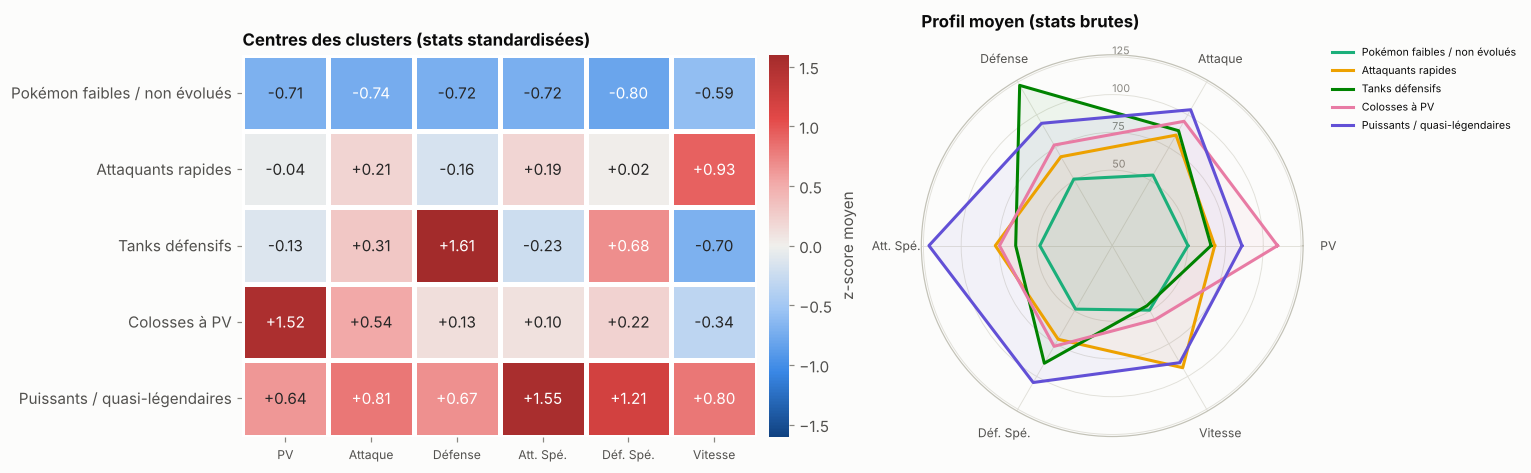

In [32]:
centres_z = pd.DataFrame(kmeans.cluster_centers_, columns=LABELS6).loc[ORDRE]
centres_z.index = [CL[c]["name"] for c in ORDRE]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw=dict(width_ratios=[1.3, 1]))
ax = axes[0]
sns.heatmap(centres_z, annot=True, fmt="+.2f", cmap=CMAP_DIV, center=0, vmin=-1.6, vmax=1.6,
            linewidths=2, linecolor="white", cbar_kws=dict(label="z-score moyen", pad=0.02), ax=ax)
ax.set(title="Centres des clusters (stats standardisées)", ylabel="")
ax.tick_params(axis="x", labelsize=8)
ax.grid(False)

ax = axes[1]
ang = np.linspace(0, 2 * np.pi, 6, endpoint=False)
ax.remove()
ax = fig.add_subplot(1, 2, 2, projection="polar")
for c in ORDRE:
    v = df.loc[kmeans.labels_ == c, STATS].mean().values
    ax.plot(np.r_[ang, ang[0]], np.r_[v, v[0]], color=COL[c], lw=2, label=CL[c]["name"])
    ax.fill(np.r_[ang, ang[0]], np.r_[v, v[0]], color=COL[c], alpha=0.06)
ax.set_xticks(ang, LABELS6, fontsize=8)
ax.set_yticks([50, 75, 100, 125], ["50", "75", "100", "125"], fontsize=7, color=MUTED)
ax.set_rlabel_position(90)
ax.tick_params(axis="x", pad=6)
ax.set_title("Profil moyen (stats brutes)", pad=18)
ax.legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.05, 1.05))
fig.tight_layout()
save_fig(fig, "18_profils_clusters")
plt.show()

In [33]:
# Pokémon les plus représentatifs (les plus proches du centre) et cas limites
dist = kmeans.transform(Z)
repr_rows = []
for c in ORDRE:
    m = np.where(kmeans.labels_ == c)[0]
    proches = m[np.argsort(dist[m, c])[:6]]
    limites = m[np.argsort(sil[m])[:3]]
    repr_rows.append({"cluster": CL[c]["name"],
                      "les plus représentatifs (proches du centre)": ", ".join(df.loc[proches, "name"]),
                      "cas limites (silhouette la plus basse)": ", ".join(df.loc[limites, "name"])})
pd.DataFrame(repr_rows).set_index("cluster")

,les plus représentatifs (proches du centre),cas limites (silhouette la plus basse)
cluster,,
Pokémon faibles / non évolués,"Snorunt, Ditto, Inkay, Grubbin, Larvitar, Mare...","Palpitoad, Weepinbell, Dustox"
Attaquants rapides,"Golbat, Swanna, Girafarig, Froslass, Stantler,...","Magby, Marshtomp, Vanillish"
Tanks défensifs,"Marowak, Crustle, Mawile, Metang, Klang, Vespi...","Tirtouga, Whirlipede, Klinklang"
Colosses à PV,"Whiscash, Seismitoad, Swalot, Exploud, Piloswi...","Ariados, Heatmor, Malamar"
Puissants / quasi-légendaires,"Hydreigon, Mesprit, Moltres, Heatran, Zapdos, ...","Terrakion, Arcanine, Espeon"


In [34]:
for c in ORDRE:
    print(f"■ {CL[c]['name']} : {CL[c]['description']}\n")

■ Pokémon faibles / non évolués : Toutes les stats sous la moyenne. Ce sont surtout des Pokémon de base ou de premier stade (Chenipan, Rattata, starters avant évolution) : ils doivent évoluer pour devenir forts.

■ Attaquants rapides : Vitesse très élevée, attaques correctes, défenses moyennes : ils frappent en premier mais encaissent mal (Électrik, Vol, Insecte évolués…).

■ Tanks défensifs : Défense (et souvent Défense spéciale) très élevée, Vitesse faible : lents mais très résistants. Beaucoup de types Roche et Acier.

■ Colosses à PV : Énorme réserve de PV et bonne Attaque, défenses dans la moyenne, plutôt lents : ils encaissent grâce à leurs PV plutôt qu'à leur armure.

■ Puissants / quasi-légendaires : Toutes les stats nettement au-dessus de la moyenne, en particulier l'Attaque spéciale et la Défense spéciale. Ce groupe rassemble la grande majorité des légendaires, les pseudo-légendaires (Dracolosse, Métalosse…) et les méga-évolutions.



**Comment les noms ont été choisis.** Le numéro d'un cluster K-means est arbitraire : il change si l'on change la graine. Le nom est donc déduit **automatiquement du centre** par une règle simple, codée dans `src/clustering.py` :

1. le cluster dont le niveau moyen est le plus bas est nommé « faibles » ;
2. celui dont le niveau moyen est le plus haut est nommé « puissants » ;
3. chaque autre cluster est nommé d'après sa **stat dominante**, c'est-à-dire la stat la plus au-dessus de son propre niveau moyen.

On a vérifié que cette règle donne les mêmes noms avec d'autres graines, et qu'elle correspond aux Pokémon représentatifs ci-dessus.

| Cluster | Signature (z-score) | Exemples typiques |
|---|---|---|
| **Pokémon faibles / non évolués** | toutes les stats autour de −0,7 | formes de base : Chenipan, Rattata, Bulbizarre, Pikachu |
| **Attaquants rapides** | Vitesse +0,9, le reste proche de 0 | Nosferalto, Starmie, Voltali |
| **Colosses à PV** | PV +1,5, Attaque +0,5, Vitesse −0,3 | Ronflex, Leuphorie, Wailord |
| **Tanks défensifs** | Défense +1,6, Déf. Spé. +0,7, Vitesse −0,7 | Caratroc, Crabaraque, Métang |
| **Puissants / quasi-légendaires** | Att. Spé. +1,5, Déf. Spé. +1,2, tout positif | Mewtwo, Électhor, Dracolosse, Métalosse |

### 2.8 Croisement avec le statut légendaire

,Non légendaire,Légendaire,% légendaires,part des légendaires
Pokémon faibles / non évolués,296,1,0.3,1.4
Attaquants rapides,183,5,2.7,7.1
Tanks défensifs,90,3,3.2,4.3
Colosses à PV,96,4,4.0,5.7
Puissants / quasi-légendaires,66,57,46.3,81.4


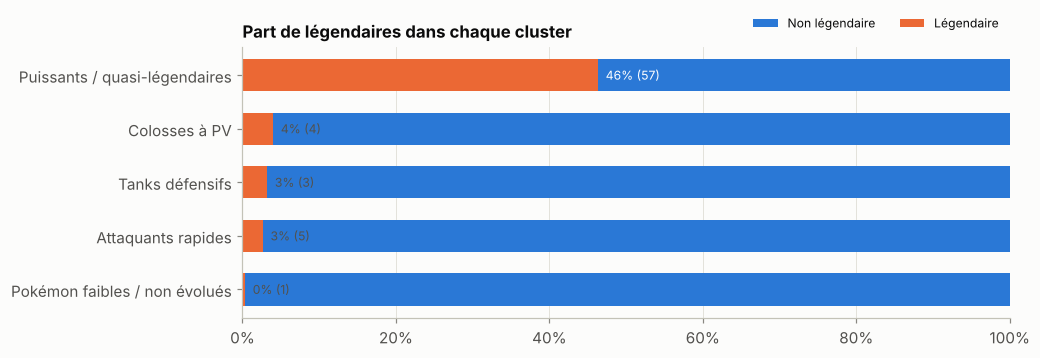

Légendaires dans « Pokémon faibles / non évolués » : Cosmog
Légendaires dans « Attaquants rapides » : Deoxys, Meloetta, Tapu Koko, Pheromosa, Kartana
Légendaires dans « Tanks défensifs » : Regirock, Registeel, Cosmoem
Légendaires dans « Colosses à PV » : Entei, Zygarde, Buzzwole, Guzzlord


In [35]:
ct_leg = pd.crosstab(df["cluster"], df[TARGET_LEGENDARY]).loc[ORDRE]
ct_leg.index = [CL[c]["name"] for c in ORDRE]
ct_leg.columns = [LEG_LABELS[k] for k in ct_leg.columns]
ct_leg["% légendaires"] = ct_leg["Légendaire"] / ct_leg.sum(axis=1) * 100
ct_leg["part des légendaires"] = ct_leg["Légendaire"] / ct_leg["Légendaire"].sum() * 100
display(ct_leg.round(1))

fig, ax = plt.subplots(figsize=(9, 3.2))
noms = ct_leg.index
pct = ct_leg["% légendaires"].values / 100
ax.barh(noms, 1 - pct, left=pct, color=COLOR_NON_LEG, height=0.6, label="Non légendaire")
ax.barh(noms, pct, color=COLOR_LEG, height=0.6, label="Légendaire")
for i, (p, n) in enumerate(zip(pct, ct_leg["Légendaire"])):
    ax.text(p + 0.01, i, f"{p:.0%} ({n})", va="center", fontsize=8,
            color="white" if p > 0.3 else INK_2)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set(title="Part de légendaires dans chaque cluster", xlim=(0, 1))
ax.legend(ncol=2, loc="lower right", fontsize=8, bbox_to_anchor=(1, 1.02))
ax.grid(axis="y", visible=False)
save_fig(fig, "19_clusters_legendaires")
plt.show()

leg = df[df[TARGET_LEGENDARY] == 1]
for c in ORDRE:
    if CL[c]["key"] != "elite":
        noms_leg = leg.loc[leg["cluster"] == c, "name"].tolist()
        print(f"Légendaires dans « {CL[c]['name']} » : {', '.join(noms_leg) or '-'}")

**Lecture**

- **Le cluster « puissants / quasi-légendaires » regroupe 57 des 70 légendaires (81 %).** Il n'a pourtant **jamais vu l'étiquette** : le clustering retrouve donc le statut légendaire uniquement à partir des stats.
- **Il n'est pas « pur »** : il compte 46 % de légendaires et 54 % de non-légendaires. Ces derniers sont les pseudo-légendaires et les méga-évolutions déjà repérés en 1.2.
- **Les 13 légendaires placés ailleurs sont des exceptions explicables :**
  - **attaquants rapides** : Deoxys, Pheromosa, Tokorico… très rapides mais fragiles ;
  - **tanks défensifs** : Regirock, Registeel, et Cosmovum (cocon) ;
  - **colosses à PV** : Entei, Guzzlord… ;
  - **faibles** : Cosmog, un « bébé » légendaire.
- **Ce qu'on en tire pour l'étape 3 :** un classifieur fondé sur les stats retrouvera facilement les légendaires « classiques ». Les cas cités ci-dessus seront ses erreurs les plus probables.

### 2.9 Croisement avec le type principal

Pour mesurer la **force du lien** entre deux variables qualitatives (cluster et type), on utilise le **V de Cramér**. Il se calcule à partir du test du χ² d'indépendance :

$$V = \sqrt{\frac{\chi^2 / n}{\min(r - 1,\, c - 1)}} \in [0, 1]$$

où $r$ et $c$ sont les nombres de lignes et de colonnes du tableau. $V = 0$ signifie que les deux variables sont indépendantes, $V = 1$ qu'elles sont liées parfaitement.

χ² = 206 (ddl = 68), p-valeur = 8.3e-16, V de Cramér = 0.25


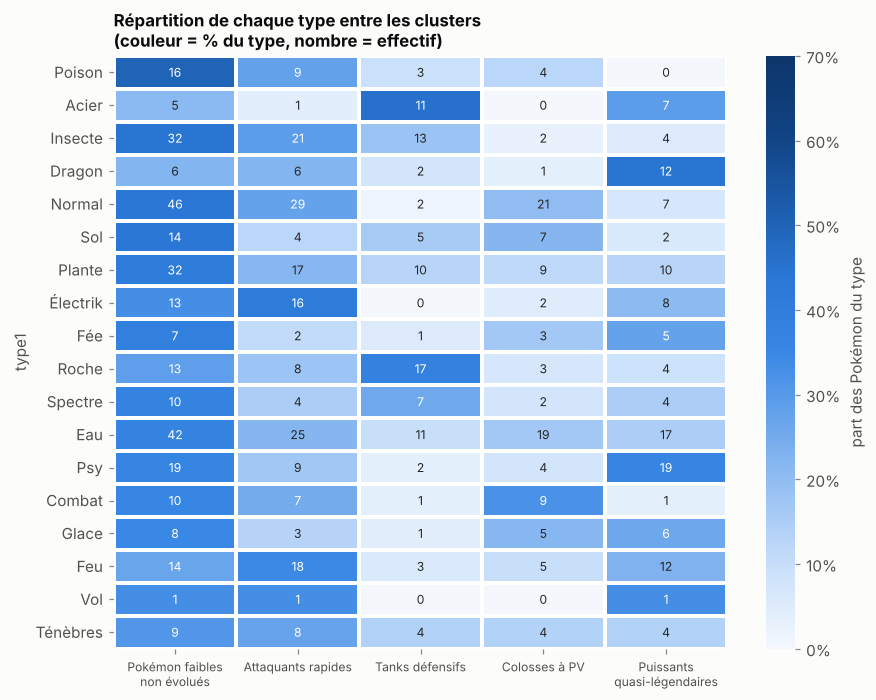

In [36]:
ct_type = pd.crosstab(df["type1"].map(TYPE_FR), df["cluster"])[ORDRE]
ct_type.columns = [CL[c]["name"] for c in ORDRE]
chi2, pval, ddl, _ = chi2_contingency(ct_type)
V = np.sqrt(chi2 / len(df) / (min(ct_type.shape) - 1))
print(f"χ² = {chi2:.0f} (ddl = {ddl}), p-valeur = {pval:.1e}, V de Cramér = {V:.2f}")

# Part de chaque type dans chaque cluster (lignes = types, somme = 100 %)
rep = ct_type.div(ct_type.sum(axis=1), axis=0)
rep = rep.loc[rep.max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(rep, annot=ct_type.loc[rep.index], fmt="d", cmap=CMAP_SEQ, vmin=0, vmax=0.7,
            linewidths=1.5, linecolor="white", cbar_kws=dict(label="part des Pokémon du type",
                                                             format=plt.matplotlib.ticker.PercentFormatter(1)),
            annot_kws=dict(fontsize=8), ax=ax)
ax.set(title="Répartition de chaque type entre les clusters\n(couleur = % du type, nombre = effectif)",
       ylabel="type1", xlabel="")
ax.set_xticklabels([t.get_text().replace(" / ", "\n") for t in ax.get_xticklabels()], rotation=0, fontsize=8)
ax.grid(False)
save_fig(fig, "20_clusters_types")
plt.show()

**Lecture**

- **Le lien entre cluster et type existe mais reste modéré** (V de Cramér = 0,25, χ² très significatif avec p < 10⁻¹⁵). Les clusters décrivent un **style de combat**, et beaucoup de types se répartissent dans plusieurs styles.
- **Les associations les plus nettes** confirment les signatures vues en 1.5 :
  - **Acier** (46 %) et **Roche** (38 %) chez les **tanks défensifs** ;
  - **Électrik** (41 %) chez les **attaquants rapides** ;
  - **Dragon** (44 %) et **Psy** (36 %) chez les **puissants**, qui sont aussi les types les plus riches en légendaires ;
  - **Poison**, **Insecte**, **Normal** et **Sol** sont surreprésentés chez les **faibles** (de 44 % à 50 %, contre 37 % pour l'ensemble des Pokémon).
- **Eau**, **Plante** et **Ténèbres** se répartissent dans tous les clusters à peu près comme l'ensemble des Pokémon, donc sans signature. On le retrouvera à l'étape 4 : ces types seront mal prédits par les stats.

### 2.10 Synthèse du clustering

| Question | Réponse |
|---|---|
| Méthode retenue | **K-means, k = 5**, sur les 6 stats standardisées (`n_init=20`, `random_state=42`) |
| Pourquoi k = 5 | silhouette dans le plateau des meilleurs k > 2 (k = 2 est trivial), Davies-Bouldin plus bas qu'à k = 4, BIC du GMM minimal à 5, profils interprétables |
| Qualité | silhouette ≈ 0,23 : structure **continue** plutôt qu'en amas séparés. Stabilité bootstrap : ARI ≈ 0,8 |
| Méthodes comparées | CAH Ward (proche de K-means, ARI ≈ 0,6). GMM `full` : modélise la densité, groupes différents et chevauchants |
| Les 5 profils | faibles / non évolués, attaquants rapides, colosses à PV, tanks défensifs, puissants / quasi-légendaires |
| Lien avec les légendaires | 81 % des légendaires dans le groupe des « puissants », alors que l'étiquette n'a jamais été utilisée |
| Lien avec les types | modéré (V = 0,25) : Acier et Roche chez les tanks, Électrik chez les rapides, Dragon et Psy chez les puissants |
| Pour l'appli | `scaler` et `kmeans` seront sauvegardés à l'étape 5. Un nouveau Pokémon est standardisé, puis rattaché au centre le plus proche |

## 3. Prédiction du statut légendaire (classification binaire)

**Question :** à partir des 6 stats seulement, quelle est la probabilité qu'un Pokémon soit légendaire ?

**Protocole anti-fuite**

1. **Découpage train/test stratifié 80/20**, fait une seule fois avec `random_state=42`. Le **test (161 Pokémon, dont 14 légendaires) est mis sous clé** : on ne le regarde qu'**une seule fois**, à la toute fin (3.11), pour évaluer le modèle choisi.
2. Toute la sélection se fait **sur le train uniquement**, par **validation croisée stratifiée à 5 plis** (`StratifiedKFold`). Le train est découpé en 5 parts qui gardent chacune environ 8,7 % de légendaires. On entraîne sur 4 parts, on évalue sur la 5ᵉ, et on fait tourner les rôles. Cela concerne :
   - le choix du modèle ;
   - le réglage des hyperparamètres ;
   - le choix du seuil de décision ;
   - la vérification de la calibration.
3. **Tout le prétraitement est dans un `Pipeline`**, qui enchaîne (total), standardisation, (SMOTE) et modèle. À chaque pli, la moyenne et l'écart-type du scaler sont recalculés **sur les 4 parts d'entraînement seulement**. La part d'évaluation reste donc « jamais vue », comme un vrai nouveau Pokémon.

In [37]:
import warnings
from time import perf_counter
from sklearn.model_selection import (StratifiedKFold, RepeatedStratifiedKFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, precision_recall_curve, roc_curve, roc_auc_score,
                             average_precision_score, precision_score, recall_score, f1_score,
                             accuracy_score, brier_score_loss, log_loss, balanced_accuracy_score,
                             ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline            # Pipeline compatible avec SMOTE
from imblearn.over_sampling import SMOTE
from src.config import N_SPLITS_CV
from src.preprocessing import split_train_test, get_X, make_preprocessor, AddTotal

df_train, df_test = split_train_test(df, stratify_col=TARGET_LEGENDARY)
X_train, y_train = get_X(df_train), df_train[TARGET_LEGENDARY]
X_test, y_test = get_X(df_test), df_test[TARGET_LEGENDARY]
print(f"train : {len(X_train)} Pokémon dont {y_train.sum()} légendaires ({y_train.mean():.1%})")
print(f"test  : {len(X_test)} Pokémon dont {y_test.sum()} légendaires ({y_test.mean():.1%})  <- sous clé")

CV5 = StratifiedKFold(n_splits=N_SPLITS_CV, shuffle=True, random_state=RANDOM_STATE)

def svm_platt(**params):
    # SVM + calibration de Platt (sigmoïde ajustée sur le score SVM, par CV interne)
    return CalibratedClassifierCV(SVC(**params), method="sigmoid", cv=5, ensemble=False)

train : 640 Pokémon dont 56 légendaires (8.8%)
test  : 161 Pokémon dont 14 légendaires (8.7%)  <- sous clé


### 3.1 Choisir les bonnes métriques

On note la classe « légendaire » comme la classe **positive**. La **matrice de confusion** croise la réalité et la prédiction :

|  | prédit non légendaire | prédit légendaire |
|---|---|---|
| **vraiment non légendaire** | VN (vrai négatif) | FP (faux positif) |
| **vraiment légendaire** | FN (faux négatif) | VP (vrai positif) |

| Métrique | Formule | Question à laquelle elle répond |
|---|---|---|
| Accuracy | $\frac{VP + VN}{n}$ | Quelle part des prédictions est correcte ? |
| **Rappel** (sensibilité) | $\frac{VP}{VP + FN}$ | Parmi les vrais légendaires, combien en retrouve-t-on ? |
| **Précision** | $\frac{VP}{VP + FP}$ | Quand le modèle dit « légendaire », a-t-il raison ? |
| **F1** | $\frac{2 \cdot P \cdot R}{P + R}$ | Moyenne **harmonique** de P et R : elle est faible dès que l'une des deux l'est |
| **ROC-AUC** | aire sous la courbe (taux de FP, rappel) | Probabilité qu'un légendaire tiré au hasard reçoive un score **plus haut** qu'un non-légendaire tiré au hasard. 0,5 = hasard, 1 = parfait |
| **PR-AUC** (*average precision*) | aire sous la courbe précision-rappel | Comme la ROC-AUC, mais centrée sur la classe **rare**. Pour un modèle aléatoire, elle vaut la **proportion de positifs** (0,087), et non 0,5 |
| **Brier** | $\frac{1}{n} \sum_i (p_i - y_i)^2$ | Erreur quadratique des **probabilités** : plus bas = mieux. Il mesure à la fois la discrimination et la calibration |
| **Log-loss** | $-\frac{1}{n} \sum_i \big[y_i \ln p_i + (1 - y_i) \ln(1 - p_i)\big]$ | Pénalise très fortement une probabilité **sûre d'elle et fausse** |

**Pourquoi l'accuracy ne suffit pas.** Un modèle qui répond **toujours** « non légendaire » ne trouve aucun légendaire, et pourtant son accuracy dépasse 91 % :

In [38]:
scoring = {"accuracy": "accuracy", "balanced_acc": "balanced_accuracy", "precision": "precision",
           "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision",
           "brier": "neg_brier_score"}

def cv_scores(model, X=X_train, y=y_train, cv=CV5):
    # Validation croisée -> dictionnaire {métrique: (moyenne, écart-type)}
    r = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1, error_score="raise")
    out = {}
    for k in scoring:
        v = r[f"test_{k}"] * (-1 if k == "brier" else 1)     # Brier : on remet le signe +
        out[k] = (v.mean(), v.std())
    return out

def fmt(res):
    # Mise en forme « moyenne ± écart-type »
    return pd.DataFrame({m: {k: f"{v[0]:.3f} ± {v[1]:.3f}" for k, v in r.items()}
                         for m, r in res.items()}).T

with warnings.catch_warnings():
    warnings.simplefilter("ignore")        # précision indéfinie (aucun positif prédit)
    base = {"Toujours « non légendaire »": cv_scores(DummyClassifier(strategy="most_frequent")),
            "Hasard (stratifié)": cv_scores(DummyClassifier(strategy="stratified",
                                                            random_state=RANDOM_STATE))}
fmt(base)[["accuracy", "recall", "precision", "f1", "roc_auc", "pr_auc"]]

,accuracy,recall,precision,f1,roc_auc,pr_auc
Toujours « non légendaire »,0.912 ± 0.003,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.087 ± 0.003
Hasard (stratifié),0.864 ± 0.014,0.126 ± 0.074,0.156 ± 0.089,0.139 ± 0.080,0.530 ± 0.040,0.103 ± 0.010


**Lecture.** Le modèle « toujours non » obtient environ **91 % d'accuracy** avec un **rappel de 0** : il ne sert à rien, mais l'accuracy ne le montre pas. C'est le piège classique des classes déséquilibrées. Pour comparer les modèles, on regardera donc d'abord :

- la **PR-AUC**, notre **critère principal**. Elle ne dépend d'aucun seuil, se concentre sur la classe rare, et sa référence est 0,087, ce qui laisse beaucoup de marge pour se distinguer ;
- la **ROC-AUC** ;
- le **Brier** et la **log-loss**, qui mesurent la qualité des probabilités. C'est indispensable ici, puisque l'appli **affiche** une probabilité ;
- le **rappel**, la **précision** et le **F1**, une fois le seuil de décision choisi (voir 3.10).

### 3.2 Une référence sans apprentissage : un seuil sur le total des stats

Avant d'utiliser des modèles, posons une **référence honnête** : prédire « légendaire » si la somme des 6 stats dépasse un seuil $t$. Le seuil est choisi sur les 4 plis d'entraînement, pour maximiser le F1. Cette règle n'utilise **que les entrées de l'appli**, donc elle ne fuit pas. Tout modèle doit faire **mieux** qu'elle pour mériter sa complexité.

In [39]:
total_train = X_train.sum(axis=1).values
rows = []
for tr_idx, va_idx in CV5.split(X_train, y_train):
    t_tr, y_tr = total_train[tr_idx], y_train.values[tr_idx]
    seuils_t = np.unique(t_tr)
    s_best = seuils_t[int(np.argmax([f1_score(y_tr, t_tr >= s) for s in seuils_t]))]
    t_va, y_va = total_train[va_idx], y_train.values[va_idx]
    pred = t_va >= s_best
    rows.append({"seuil": s_best, "recall": recall_score(y_va, pred),
                 "precision": precision_score(y_va, pred), "f1": f1_score(y_va, pred),
                 "roc_auc": roc_auc_score(y_va, t_va), "pr_auc": average_precision_score(y_va, t_va)})
regle = pd.DataFrame(rows)
print("Seuil choisi dans chaque pli :", regle["seuil"].tolist())
display(regle.drop(columns="seuil").agg(["mean", "std"]).round(3))

leg_tr = df_train[df_train[TARGET_LEGENDARY] == 1]
print("Totaux les plus fréquents chez les légendaires du train :",
      leg_tr["base_total"].value_counts().head(5).to_dict())
print(f"Non-légendaires du train avec total >= 570 : {((total_train >= 570) & (y_train == 0)).sum()}"
      f" | légendaires avec total < 570 : {((total_train < 570) & (y_train == 1)).sum()}")

Seuil choisi dans chaque pli : [570, 570, 570, 570, 570]


,recall,precision,f1,roc_auc,pr_auc
mean,0.98,0.66,0.78,0.95,0.70
std,0.04,0.18,0.11,0.03,0.13


Totaux les plus fréquents chez les légendaires du train : {580: 14, 600: 14, 680: 11, 570: 8, 700: 3}
Non-légendaires du train avec total >= 570 : 34 | légendaires avec total < 570 : 1


**Lecture : une référence redoutable.** La règle **« total ≥ 570 »**, choisie dans chacun des 5 plis, retrouve **presque tous les légendaires** (rappel ≈ 0,98) avec une précision d'environ 0,66, soit un **F1 d'environ 0,78**.

**Pourquoi.** Les concepteurs du jeu attribuent aux légendaires des **totaux « ronds »** : 570 pour les Tokos et les Ultra-Chimères, 580 pour les oiseaux légendaires, 600, 680… Il y a donc une **marche** dans les données à 570. Seuls les non-légendaires très forts (pseudo-légendaires, méga-évolutions) la franchissent.

Mais la règle ne donne **pas de probabilité**, ce qui explique sa PR-AUC plus modeste (≈ 0,70). **Ce qu'on en tire pour la suite :** un bon modèle devra au moins **savoir exploiter ce total** (voir 3.5).

### 3.3 Le modèle de base : la régression logistique

**Le modèle.** On calcule une combinaison linéaire des stats standardisées, le **logit** (log-cote) :

$$\eta = \beta_0 + \sum_{j=1}^{6} \beta_j z_j$$

La **sigmoïde** transforme ce score réel en probabilité :

$$p = P(\text{légendaire} \mid \mathbf{z}) = \sigma(\eta) = \frac{1}{1 + e^{-\eta}}$$

$\sigma$ est croissante, vaut 0,5 en $\eta = 0$ et tend vers 0 ou 1 aux extrêmes. On a l'équivalence

$$\ln \frac{p}{1 - p} = \eta$$

Le **logit est linéaire** en les stats : $e^{\beta_j}$ est le facteur multiplicatif de la **cote** $\frac{p}{1 - p}$ quand la stat $j$ augmente d'un écart-type.

**L'apprentissage.** On cherche les $\beta$ qui **maximisent la vraisemblance** des données, ce qui revient à **minimiser la log-loss** (entropie croisée), plus une pénalité $L_2$ :

$$\min_{\boldsymbol{\beta}} \; -\sum_i \big[y_i \ln p_i + (1 - y_i) \ln(1 - p_i)\big] + \frac{1}{2C} \|\boldsymbol{\beta}\|^2$$

- **Plus $C$ est petit, plus la régularisation est forte :** les coefficients sont « tirés » vers 0, ce qui limite le surapprentissage.
- **Le problème est convexe :** il a un minimum unique, que l'on trouve par une méthode de type Newton (le solveur `lbfgs`).
- **La log-loss est une *règle de score propre*.** Elle est minimale quand $p$ est la **vraie** probabilité. C'est pourquoi la régression logistique produit naturellement des probabilités **bien calibrées**. On le vérifiera en 3.9.

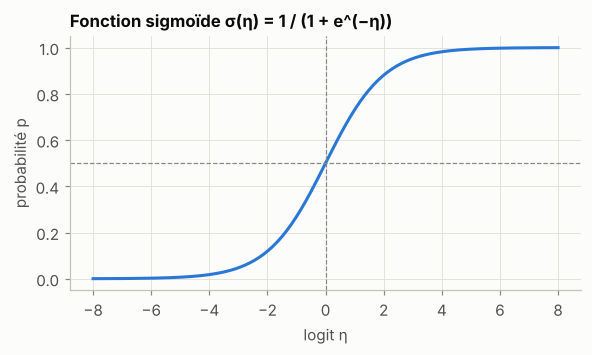

In [40]:
eta = np.linspace(-8, 8, 200)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(eta, 1 / (1 + np.exp(-eta)), color=SERIES[0])
ax.axhline(0.5, color=MUTED, lw=0.8, ls="--"); ax.axvline(0, color=MUTED, lw=0.8, ls="--")
ax.set(title="Fonction sigmoïde σ(η) = 1 / (1 + e^(−η))", xlabel="logit η", ylabel="probabilité p")
save_fig(fig, "21_sigmoide")
plt.show()

### 3.4 Comparaison des 6 modèles et des 3 stratégies contre le déséquilibre

**Les modèles**

| Modèle | Idée | Mise à l'échelle nécessaire ? |
|---|---|---|
| Régression logistique | frontière **linéaire** dans l'espace des stats, puis sigmoïde | oui (pénalité L2) |
| k-NN | vote des $k$ voisins les plus proches (distance euclidienne) | **oui** |
| Arbre de décision | questions successives « stat > seuil ? » qui maximisent la pureté (indice de Gini) | non |
| Random Forest | moyenne de centaines d'arbres entraînés sur des échantillons bootstrap, avec des variables tirées au hasard | non |
| SVM à noyau RBF | marge maximale dans un espace transformé par le noyau $K(\mathbf{x}, \mathbf{x}') = e^{-\gamma \|\mathbf{x} - \mathbf{x}'\|^2}$, puis calibration de Platt pour obtenir une probabilité | **oui** |
| Gradient boosting | arbres peu profonds ajoutés un à un, chacun corrigeant les erreurs des précédents (descente de gradient sur la log-loss) | non |

**Les stratégies contre le déséquilibre**

- **`none`** : on entraîne sans rien changer.
- **`class_weight="balanced"`** : chaque légendaire compte $w = \frac{n_{\text{non}}}{n_{\text{lég}}} \approx 10$ fois plus dans la fonction de coût. Le modèle est puni 10 fois plus fort quand il rate un légendaire. Le k-NN n'a pas cette option.
- **SMOTE** (*Synthetic Minority Over-sampling*) : on fabrique des légendaires **synthétiques** en interpolant entre un légendaire et l'un de ses $k$ voisins légendaires, $\mathbf{x}_{\text{new}} = \mathbf{x}_i + \lambda (\mathbf{x}_{\text{voisin}} - \mathbf{x}_i)$ avec $\lambda \sim \mathcal{U}(0, 1)$, jusqu'à obtenir 50/50. Grâce au `Pipeline` d'*imbalanced-learn*, **SMOTE n'est appliqué que pendant `fit`**, donc sur les plis d'entraînement. Les Pokémon d'évaluation restent réels.

Ici, on utilise les **6 stats brutes** et les hyperparamètres **par défaut**. Les variables seront enrichies en 3.5 et les hyperparamètres réglés en 3.6.

In [41]:
def make_pipe(model, strategy="none"):
    steps = [("scaler", StandardScaler())]
    if strategy == "smote":
        steps.append(("sampler", SMOTE(random_state=RANDOM_STATE)))
    steps.append(("model", model))
    return Pipeline(steps)

def base_models(cw):
    return {
        "Régression logistique": LogisticRegression(class_weight=cw, max_iter=5000),
        "k-NN": None if cw else KNeighborsClassifier(n_neighbors=7),
        "Arbre de décision": DecisionTreeClassifier(max_depth=4, class_weight=cw, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=300, class_weight=cw,
                                                random_state=RANDOM_STATE, n_jobs=1),
        "SVM (RBF)": svm_platt(class_weight=cw),
        "Gradient boosting": HistGradientBoostingClassifier(class_weight=cw, random_state=RANDOM_STATE),
    }

comparaison = {}
for strategy in ["none", "balanced", "smote"]:
    for nom, model in base_models("balanced" if strategy == "balanced" else None).items():
        if model is not None:
            comparaison[(nom, strategy)] = cv_scores(make_pipe(model, strategy))

comp = pd.DataFrame({k: {m: v[0] for m, v in r.items()} for k, r in comparaison.items()}).T
comp_std = pd.DataFrame({k: {m: v[1] for m, v in r.items()} for k, r in comparaison.items()}).T
comp.index.names = comp_std.index.names = ["modèle", "stratégie"]
cols = ["recall", "precision", "f1", "roc_auc", "pr_auc", "brier"]
(comp[cols].round(3).astype(str) + " ± " + comp_std[cols].round(2).astype(str))

,,recall,precision,f1,roc_auc,pr_auc,brier
modèle,stratégie,,,,,,
Régression logistique,none,0.377 ± 0.08,0.65 ± 0.25,0.463 ± 0.1,0.952 ± 0.03,0.732 ± 0.1,0.046 ± 0.01
k-NN,none,0.5 ± 0.17,0.737 ± 0.17,0.561 ± 0.12,0.925 ± 0.03,0.629 ± 0.07,0.047 ± 0.01
Arbre de décision,none,0.47 ± 0.19,0.546 ± 0.2,0.486 ± 0.16,0.759 ± 0.08,0.394 ± 0.09,0.07 ± 0.02
Random Forest,none,0.414 ± 0.1,0.715 ± 0.2,0.502 ± 0.08,0.933 ± 0.03,0.684 ± 0.07,0.049 ± 0.01
SVM (RBF),none,0.486 ± 0.17,0.72 ± 0.23,0.552 ± 0.15,0.96 ± 0.02,0.749 ± 0.11,0.045 ± 0.02
Gradient boosting,none,0.505 ± 0.17,0.656 ± 0.16,0.549 ± 0.14,0.919 ± 0.05,0.676 ± 0.1,0.055 ± 0.02
Régression logistique,balanced,0.948 ± 0.07,0.501 ± 0.11,0.647 ± 0.1,0.953 ± 0.03,0.739 ± 0.1,0.076 ± 0.03
Arbre de décision,balanced,0.703 ± 0.2,0.341 ± 0.07,0.457 ± 0.1,0.794 ± 0.09,0.347 ± 0.08,0.12 ± 0.01
Random Forest,balanced,0.612 ± 0.19,0.681 ± 0.14,0.618 ± 0.12,0.925 ± 0.04,0.689 ± 0.07,0.05 ± 0.01


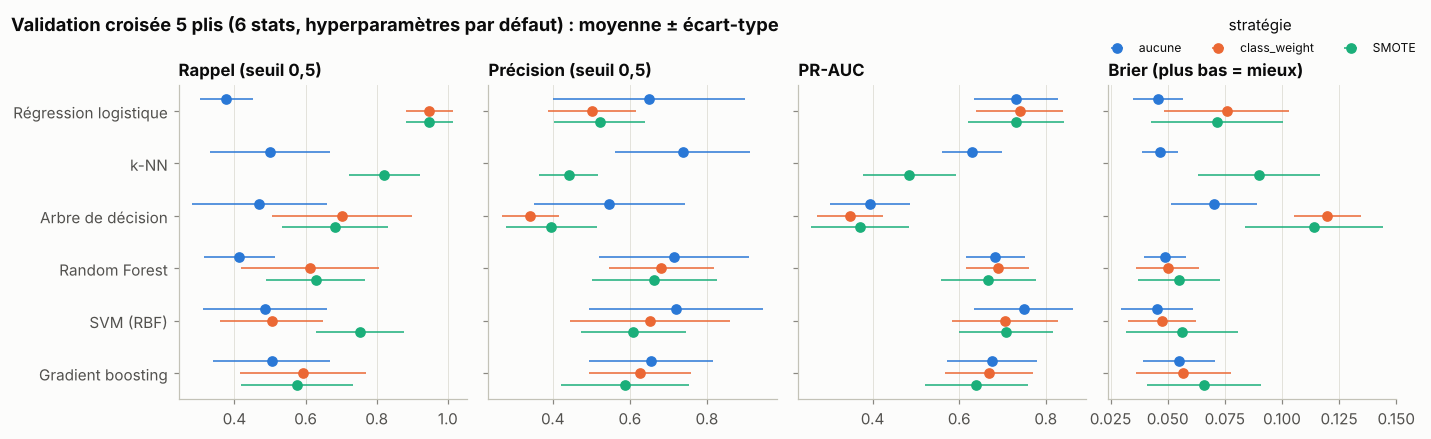

In [42]:
fig, axes = plt.subplots(1, 4, figsize=(13, 4), sharey=True)
modeles = list(base_models(None))
strat_col = {"none": SERIES[0], "balanced": SERIES[1], "smote": SERIES[2]}
strat_lab = {"none": "aucune", "balanced": "class_weight", "smote": "SMOTE"}
for ax, (met, titre) in zip(axes, [("recall", "Rappel (seuil 0,5)"), ("precision", "Précision (seuil 0,5)"),
                                   ("pr_auc", "PR-AUC"), ("brier", "Brier (plus bas = mieux)")]):
    for j, s in enumerate(["none", "balanced", "smote"]):
        ys = [i + (j - 1) * 0.22 for i in range(len(modeles))]
        vals = [comp.loc[(m, s), met] if (m, s) in comp.index else np.nan for m in modeles]
        errs = [comp_std.loc[(m, s), met] if (m, s) in comp.index else np.nan for m in modeles]
        ax.errorbar(vals, ys, xerr=errs, fmt="o", ms=6, color=strat_col[s], ecolor=strat_col[s],
                    elinewidth=1, capsize=0, label=strat_lab[s])
    ax.set_title(titre)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(modeles)), modeles)
axes[0].invert_yaxis()
fig.suptitle("Validation croisée 5 plis (6 stats, hyperparamètres par défaut) : moyenne ± écart-type",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, title="stratégie", fontsize=8, ncol=3, loc="upper right", bbox_to_anchor=(1, 1.0))
save_fig(fig, "22_strategies_desequilibre")
plt.show()

**Lecture : ce que changent vraiment `class_weight` et SMOTE**

1. **Au seuil de 0,5, le rééquilibrage fait exploser le rappel**, au prix de la précision. La régression logistique passe d'environ 0,4 à 0,95 de rappel, sa précision tombe à environ 0,5. Sans rééquilibrage, le modèle est « timide » : il dit rarement légendaire, et il a statistiquement raison de l'être, puisque seuls 8,7 % des Pokémon le sont.
2. **La PR-AUC et la ROC-AUC ne bougent presque pas.** Ces deux mesures évaluent l'**ordre** des scores (est-ce que les légendaires sont classés au-dessus des autres ?) et non le seuil. **Le rééquilibrage ne rend donc pas le modèle meilleur pour reconnaître les légendaires : il déplace seulement son seuil.**
3. **En revanche, il dégrade souvent le Brier, c'est-à-dire la qualité des probabilités.** Pour la régression logistique, le Brier passe d'environ 0,046 à 0,076. Le modèle annonce des probabilités **gonflées**.

**Explication mathématique.** Donner un poids $w$ aux positifs revient à faire comme si les légendaires étaient $w$ fois plus fréquents. La cote estimée est alors multipliée par environ $w$, donc le logit est décalé d'environ $\ln w$. Seule l'ordonnée à l'origine $\beta_0$ change, les autres coefficients restent presque identiques. On le vérifie :

In [43]:
w = (y_train == 0).sum() / (y_train == 1).sum()
lr_none = make_pipe(LogisticRegression(max_iter=5000)).fit(X_train, y_train)["model"]
lr_bal = make_pipe(LogisticRegression(class_weight="balanced", max_iter=5000)).fit(X_train, y_train)["model"]
print(f"w = n_non / n_lég = {w:.1f}   ->   ln(w) = {np.log(w):.2f}")
print(f"β0 sans poids = {lr_none.intercept_[0]:.2f} | β0 avec poids = {lr_bal.intercept_[0]:.2f} "
      f"| décalage = {lr_bal.intercept_[0] - lr_none.intercept_[0]:.2f}")
pd.DataFrame({"β sans poids": lr_none.coef_[0], "β balanced": lr_bal.coef_[0]}, index=LABELS6).round(2).T

w = n_non / n_lég = 10.4   ->   ln(w) = 2.34
β0 sans poids = -5.06 | β0 avec poids = -3.01 | décalage = 2.05


,PV,Attaque,Défense,Att. Spé.,Déf. Spé.,Vitesse
β sans poids,0.93,0.28,0.76,0.97,0.75,1.15
β balanced,0.93,0.35,0.84,1.00,0.68,1.13


**Conclusion pour la suite.** L'appli doit afficher une **probabilité honnête**. Le rééquilibrage ne classe pas mieux et fausse les probabilités. On gère donc le déséquilibre ainsi :

- on classe les modèles avec des **métriques insensibles au seuil et adaptées à la classe rare** : PR-AUC, puis Brier et log-loss ;
- on entraîne **sans pondération** ;
- on choisit ensuite **explicitement le seuil** de décision (3.10), au lieu de laisser le rééquilibrage le déplacer implicitement.

### 3.5 Ingénierie de variable : redonner le total aux arbres

La référence de 3.2 montre que le **total** est un signal très fort, avec une « marche » à 570. Or les modèles ne l'exploitent pas tous de la même façon :

- **La régression logistique et le SVM** combinent les stats entre elles. Le total ($= \sum_j x_j$) est une combinaison linéaire qu'ils peuvent reconstruire seuls. Pour la logistique, l'ajouter crée même une **colinéarité exacte**, sans rien apporter.
- **Un arbre ne pose que des questions sur une variable à la fois** (« Att. Spé. > 110 ? »). Ses frontières sont parallèles aux axes. Pour approcher la frontière oblique $x_1 + \dots + x_6 = 570$, il lui faudrait un escalier de dizaines de coupures. Lui **donner le total** lui permet de la réaliser **en une seule question**.

On ajoute donc une étape `AddTotal` en tête du pipeline. Elle calcule le total **à partir des 6 stats reçues en entrée**, ce qui n'est **pas une fuite**, puisque l'appli peut faire exactement la même chose. Comparons chaque modèle **avec et sans** cette variable :

In [44]:
def make_pipe_f(model, total):
    return Pipeline(([("features", AddTotal())] if total else []) +
                    [("scaler", StandardScaler()), ("model", model)])

avec_total = {}
for nom, model in base_models(None).items():
    for total in (False, True):
        r = cross_validate(make_pipe_f(model, total), X_train, y_train, cv=CV5,
                           scoring={"pr_auc": "average_precision", "brier": "neg_brier_score"}, n_jobs=-1)
        avec_total[(nom, "6 stats + total" if total else "6 stats")] = {
            "PR-AUC": r["test_pr_auc"].mean(), "Brier": -r["test_brier"].mean()}
tab_tot = pd.DataFrame(avec_total).T.unstack()
tab_tot[("PR-AUC", "gain")] = tab_tot[("PR-AUC", "6 stats + total")] - tab_tot[("PR-AUC", "6 stats")]
tab_tot.round(3)

PR-AUC                   Brier                 PR-AUC
                      6 stats 6 stats + total 6 stats 6 stats + total   gain
Arbre de décision        0.39            0.64    0.07            0.05   0.25
Gradient boosting        0.68            0.83    0.06            0.04   0.15
Random Forest            0.68            0.82    0.05            0.04   0.14
Régression logistique    0.73            0.73    0.05            0.05   0.00
SVM (RBF)                0.75            0.73    0.04            0.04  -0.02
k-NN                     0.63            0.66    0.05            0.05   0.03

**Lecture : un gain spectaculaire pour les arbres, et rien pour les modèles linéaires**

- **L'arbre de décision, la Random Forest et le gradient boosting gagnent beaucoup en PR-AUC** (de +0,1 à +0,3), et leur Brier baisse nettement. L'arbre de décision progresse le plus, car c'est lui qui « souffrait » le plus de ses frontières parallèles aux axes.
- **La régression logistique et le SVM ne changent presque pas**, comme prévu : ils savaient déjà former cette combinaison.
- **Leçon de méthode :** la colonne `base_total` du CSV avait été écartée comme **redondante** (0.4). C'est vrai pour un modèle linéaire, **faux pour un arbre**. La redondance dépend du modèle.

L'option « avec ou sans total » devient un **hyperparamètre** de la recherche par grille.

### 3.6 Réglage des hyperparamètres (GridSearchCV)

Pour chaque modèle, `GridSearchCV` essaie **toutes les combinaisons** de la grille. Chaque combinaison est évaluée par validation croisée stratifiée à 5 plis **sur le train**, avec pour critère la **PR-AUC**. On garde la meilleure. La grille comprend l'étape `features` : `passthrough` (6 stats) ou `AddTotal` (6 stats + total). Suivant la conclusion de 3.4, on n'utilise **pas de pondération**.

Signification des principaux hyperparamètres :
- `C` (logistique, SVM) : l'inverse de la force de régularisation ;
- `gamma` (SVM) : la portée d'influence d'un point. Plus il est grand, plus la frontière est sinueuse ;
- `n_neighbors` (k-NN) : le nombre de voisins ;
- `max_depth`, `min_samples_leaf`, `max_features` (arbres) : ils limitent la complexité des arbres ;
- `learning_rate`, `max_iter` (boosting) : le pas d'apprentissage et le nombre d'arbres ajoutés.

In [45]:
def pipe_grid(model):
    return Pipeline([("features", "passthrough"), ("scaler", StandardScaler()), ("model", model)])

FEATURES = ["passthrough", AddTotal()]
grilles = {
    "Régression logistique": (pipe_grid(LogisticRegression(max_iter=5000)),
        {"features": FEATURES, "model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}),
    "k-NN": (pipe_grid(KNeighborsClassifier()),
        {"features": FEATURES, "model__n_neighbors": [5, 11, 21, 31, 51],
         "model__weights": ["uniform", "distance"]}),
    "Arbre de décision": (pipe_grid(DecisionTreeClassifier(random_state=RANDOM_STATE)),
        {"features": FEATURES, "model__max_depth": [2, 3, 4, 6], "model__min_samples_leaf": [1, 5, 10, 20]}),
    "Random Forest": (pipe_grid(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)),
        {"features": FEATURES, "model__max_depth": [None, 5], "model__min_samples_leaf": [1, 3, 5],
         "model__max_features": ["sqrt", None]}),
    "SVM (RBF)": (pipe_grid(svm_platt()),
        {"features": FEATURES, "model__estimator__C": [0.03, 0.1, 0.3, 1, 10],
         "model__estimator__gamma": ["scale", 0.01, 0.03, 0.1, 0.3]}),
    "Gradient boosting": (pipe_grid(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
        {"features": FEATURES, "model__learning_rate": [0.03, 0.1], "model__max_depth": [2, 3],
         "model__max_iter": [100, 300], "model__min_samples_leaf": [5, 20]}),
}

meilleurs, recap = {}, []
for nom, (pipe, grille) in grilles.items():
    t0 = perf_counter()
    gs = GridSearchCV(pipe, grille, cv=CV5, scoring="average_precision", n_jobs=-1).fit(X_train, y_train)
    meilleurs[nom] = gs.best_estimator_
    params = {k.replace("model__", "").replace("estimator__", ""):
              ("6 stats + total" if k == "features" and not isinstance(v, str) else
               "6 stats" if k == "features" else v) for k, v in gs.best_params_.items()}
    recap.append({"modèle": nom, "PR-AUC (CV)": gs.best_score_,
                  "± écart-type": gs.cv_results_["std_test_score"][gs.best_index_],
                  "combinaisons": len(gs.cv_results_["params"]), "durée (s)": perf_counter() - t0,
                  "meilleurs hyperparamètres": params})
pd.set_option("display.max_colwidth", 200)
pd.DataFrame(recap).set_index("modèle").round(3)

,PR-AUC (CV),± écart-type,combinaisons,durée (s),meilleurs hyperparamètres
modèle,,,,,
Régression logistique,0.73,0.10,14,0.22,"{'features': '6 stats', 'C': 3}"
k-NN,0.78,0.07,20,0.33,"{'features': '6 stats + total', 'n_neighbors': 31, 'weights': 'distance'}"
Arbre de décision,0.79,0.15,32,0.39,"{'features': '6 stats + total', 'max_depth': 3, 'min_samples_leaf': 10}"
Random Forest,0.84,0.07,24,10.59,"{'features': '6 stats + total', 'max_depth': 5, 'max_features': None, 'min_samples_leaf': 5}"
SVM (RBF),0.76,0.11,50,1.83,"{'features': '6 stats', 'C': 0.3, 'gamma': 0.3}"
Gradient boosting,0.85,0.04,32,2.53,"{'features': '6 stats + total', 'learning_rate': 0.1, 'max_depth': 3, 'max_iter': 100, 'min_samples_leaf': 5}"


**Lecture**

- **La grille choisit le total pour tous les modèles à base d'arbres et pour le k-NN**, mais pas pour la logistique ni le SVM. C'est cohérent avec 3.5.
- **Le gradient boosting et la Random Forest passent en tête** (PR-AUC ≈ 0,85 sur ces 5 plis), devant le SVM et la logistique (≈ 0,73–0,76).
- **Attention à l'optimisme :** ces scores sont ceux de la **meilleure** combinaison parmi des dizaines, sur les mêmes plis qui ont servi à la choisir. Ils sont donc légèrement **surestimés**. De plus, l'écart-type entre plis vaut environ 0,1 : avec 11 légendaires par pli d'évaluation, un seul légendaire mal classé fait varier la PR-AUC de plusieurs points.

Pour une comparaison juste, il faut évaluer les modèles réglés sur **d'autres découpages**.

### 3.7 Comparaison robuste : validation croisée répétée

On répète **10 fois** la validation croisée stratifiée à 5 plis, chaque fois avec un découpage **différent** de celui du réglage, ce qui donne **50 évaluations par modèle**. Tous les modèles voient **exactement les mêmes plis**. On peut donc les comparer **pli par pli** (comparaison appariée), ce qui élimine la variabilité due au découpage.

In [46]:
RCV = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE + 1)
score_rep = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "brier": "neg_brier_score",
             "log_loss": "neg_log_loss"}
rep_raw = {}
for nom, m in meilleurs.items():
    r = cross_validate(m, X_train, y_train, cv=RCV, scoring=score_rep, n_jobs=-1)
    rep_raw[nom] = {k: r[f"test_{k}"] * (1 if k in ("pr_auc", "roc_auc") else -1) for k in score_rep}
    rep_raw[nom]["fit_time"] = r["fit_time"]
    m.fit(X_train, y_train)                       # temps de prédiction d'un seul Pokémon
    un = X_train.iloc[:1]
    t0 = perf_counter()
    for _ in range(20):
        m.predict_proba(un)
    rep_raw[nom]["predict_ms"] = (perf_counter() - t0) / 20 * 1000

tab_rep = pd.DataFrame({nom: {k: f"{v.mean():.3f} ± {v.std():.3f}" for k, v in d.items()
                              if k in score_rep} for nom, d in rep_raw.items()}).T
tab_rep["entraînement (ms)"] = [f"{d['fit_time'].mean() * 1000:.0f}" for d in rep_raw.values()]
tab_rep["prédiction d'1 Pokémon (ms)"] = [f"{d['predict_ms']:.1f}" for d in rep_raw.values()]
tab_rep = tab_rep.loc[sorted(rep_raw, key=lambda n: -rep_raw[n]["pr_auc"].mean())]
tab_rep

,pr_auc,roc_auc,brier,log_loss,entraînement (ms),prédiction d'1 Pokémon (ms)
Gradient boosting,0.795 ± 0.096,0.966 ± 0.031,0.036 ± 0.012,0.128 ± 0.047,34,2.9
Random Forest,0.794 ± 0.107,0.973 ± 0.021,0.032 ± 0.009,0.146 ± 0.115,304,14.6
Arbre de décision,0.772 ± 0.103,0.975 ± 0.019,0.031 ± 0.010,0.246 ± 0.198,5,1.9
k-NN,0.742 ± 0.102,0.961 ± 0.027,0.041 ± 0.008,0.175 ± 0.114,6,2.5
SVM (RBF),0.718 ± 0.112,0.962 ± 0.020,0.048 ± 0.011,0.167 ± 0.034,23,1.6
Régression logistique,0.697 ± 0.124,0.950 ± 0.039,0.046 ± 0.012,0.158 ± 0.053,5,1.0


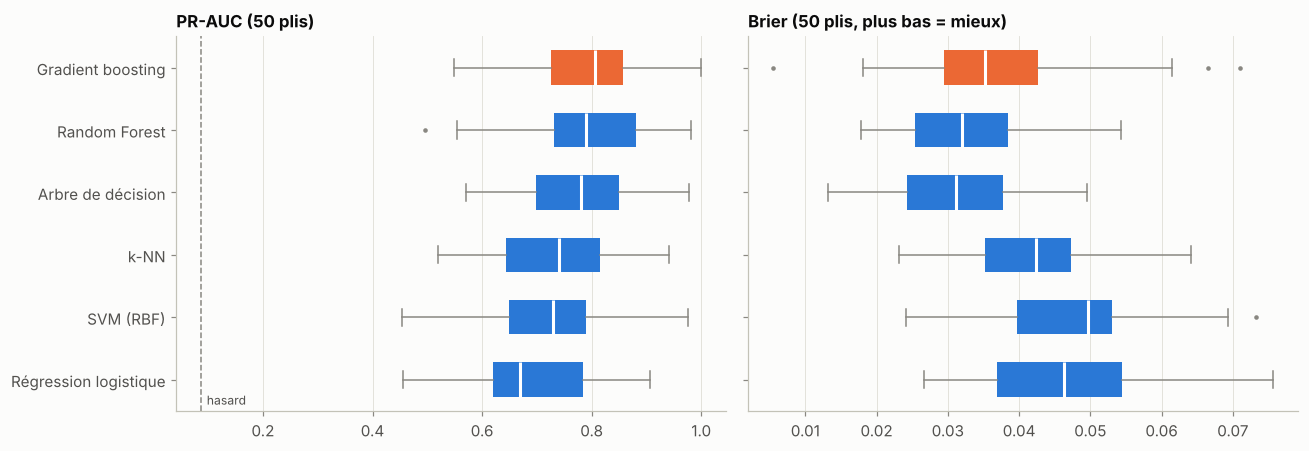

,écart moyen de PR-AUC,% des plis où le boosting gagne,écart moyen de log-loss
Régression logistique,9.80e-02,80.0,-0.03
k-NN,5.30e-02,74.0,-0.05
Arbre de décision,2.20e-02,58.0,-0.12
Random Forest,1.00e-03,54.0,-0.02
SVM (RBF),7.70e-02,82.0,-0.04


In [47]:
ordre_m = sorted(rep_raw, key=lambda n: np.median(rep_raw[n]["pr_auc"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, met, titre in [(axes[0], "pr_auc", "PR-AUC (50 plis)"),
                       (axes[1], "brier", "Brier (50 plis, plus bas = mieux)")]:
    bp = ax.boxplot([rep_raw[n][met] for n in ordre_m], orientation="horizontal", widths=0.55,
                    patch_artist=True, medianprops=dict(color="white", lw=2),
                    whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
                    flierprops=dict(marker="o", ms=3, mfc=MUTED, mec="none"))
    for patch, n in zip(bp["boxes"], ordre_m):
        patch.set_facecolor(SERIES[1] if n == "Gradient boosting" else SERIES[0])
        patch.set_edgecolor("none")
    ax.set_title(titre)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(1, len(ordre_m) + 1), ordre_m)
axes[0].axvline(y_train.mean(), color=MUTED, ls="--", lw=1)
axes[0].text(y_train.mean() + 0.01, 0.6, "hasard", fontsize=8, color=INK_2)
fig.tight_layout()
save_fig(fig, "23_comparaison_cv_repetee")
plt.show()

ref = "Gradient boosting"
apparie = pd.DataFrame({autre: {"écart moyen de PR-AUC": (rep_raw[ref]["pr_auc"] - rep_raw[autre]["pr_auc"]).mean(),
                                "% des plis où le boosting gagne": (rep_raw[ref]["pr_auc"] > rep_raw[autre]["pr_auc"]).mean() * 100,
                                "écart moyen de log-loss": (rep_raw[ref]["log_loss"] - rep_raw[autre]["log_loss"]).mean()}
                        for autre in rep_raw if autre != ref}).T
apparie.round(3)

In [48]:
# Un défaut rédhibitoire du k-NN pondéré par la distance pour NOTRE appli :
# un Pokémon déjà vu à l'entraînement est à distance 0 de lui-même -> poids infini.
knn_best = meilleurs["k-NN"].fit(X_train, y_train)
print("k-NN retenu :", knn_best["model"].n_neighbors, "voisins, poids =", knn_best["model"].weights)
p_train_leg = knn_best.predict_proba(X_train[y_train == 1])[:, 1]
print(f"Probabilité affichée pour les légendaires du TRAIN : min {p_train_leg.min():.2f}, "
      f"moyenne {p_train_leg.mean():.2f}")

k-NN retenu : 31 voisins, poids = distance
Probabilité affichée pour les légendaires du TRAIN : min 1.00, moyenne 1.00


**Lecture et choix du modèle**

- **Les trois modèles à base d'arbres, qui utilisent le total, sont en tête.** Le gradient boosting et la Random Forest atteignent une PR-AUC d'environ 0,80, suivis d'un simple arbre de profondeur 3 (environ 0,77). Le k-NN, le SVM et la logistique se situent entre 0,70 et 0,74.
  - Le boosting bat le SVM, la logistique et le k-NN sur **74 à 82 % des plis appariés** : l'écart est **réel**, pas un effet du découpage.
  - Entre boosting et Random Forest, en revanche, c'est **l'égalité** : le boosting gagne environ un pli sur deux.
- **Pour départager les arbres, on regarde la qualité des probabilités et le coût :**
  - **L'arbre seul** a une très mauvaise log-loss (environ 0,25, avec une forte variance). Ses feuilles donnent des probabilités « tout ou rien », souvent fausses avec assurance. Il est écarté pour l'appli.
  - **Le boosting a la meilleure log-loss** (environ 0,13). Il est entraîné en minimisant directement la log-loss, une règle de score propre (3.3).
  - Les probabilités d'une **Random Forest** sont des moyennes de votes d'arbres, qui atteignent rarement 0 ou 1.
  - **Le boosting est environ 7 fois plus rapide à entraîner et 6 fois plus rapide à prédire.**
- **Le k-NN est écarté pour l'appli.** Avec la pondération par la distance, un Pokémon déjà vu à l'entraînement est à distance 0 de lui-même : son vote reçoit un poids infini. L'appli afficherait **100 % ou 0 %** pour tout Pokémon existant choisi dans la liste, ce qui revient à **réciter les étiquettes**. C'est une mémorisation que la validation croisée ne voit pas.
- **La régression logistique** reste la plus simple et la plus lisible. On s'en sert en 3.8 pour **expliquer** ce qui fait un légendaire.

**Modèle retenu pour le statut légendaire : gradient boosting (`HistGradientBoostingClassifier`) sur les 6 stats + le total, sans pondération.** Ses hyperparamètres sont ceux trouvés en 3.6.

### 3.8 Interprétation : qu'est-ce qui fait un légendaire ?

**a) Régression logistique : les coefficients.** Les stats étant standardisées, les coefficients sont **comparables** entre eux. L'*odds ratio* $e^{\beta_j}$ indique par combien la **cote** d'être légendaire est multipliée quand la stat augmente d'**un écart-type** (environ 27 à 32 points), les autres stats étant fixées.

**b) Boosting retenu : l'importance par permutation.** Sur chaque pli d'évaluation, on **mélange au hasard** une stat entre les Pokémon, puis on mesure la **baisse de PR-AUC** qui en résulte. Une stat importante fait chuter le score quand on la rend aléatoire. Le total est recalculé **dans** le pipeline : permuter une stat brouille donc aussi le total, et l'importance mesurée inclut ce double effet.

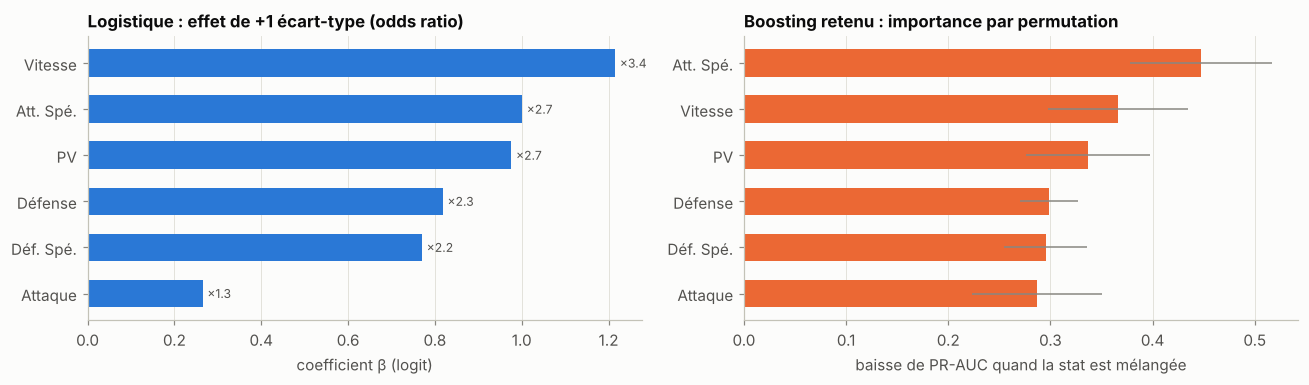

Logistique : β0 = -5.23 -> Pokémon parfaitement moyen : p = 0.5%


In [49]:
lr_interp = make_pipe(LogisticRegression(C=meilleurs["Régression logistique"]["model"].C, max_iter=5000)).fit(X_train, y_train)["model"]
coef = pd.DataFrame({"β (par écart-type)": lr_interp.coef_[0], "odds ratio e^β": np.exp(lr_interp.coef_[0])},
                    index=LABELS6)

imp = []
for tr_idx, va_idx in CV5.split(X_train, y_train):
    m = meilleurs["Gradient boosting"].fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    r = permutation_importance(m, X_train.iloc[va_idx], y_train.iloc[va_idx], scoring="average_precision",
                               n_repeats=20, random_state=RANDOM_STATE)
    imp.append(r.importances_mean)
imp = pd.DataFrame(imp, columns=LABELS6)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
c = coef.sort_values("β (par écart-type)")
bars = axes[0].barh(c.index, c["β (par écart-type)"], color=SERIES[0], height=0.6)
axes[0].bar_label(bars, labels=[f"×{v:.1f}" for v in c["odds ratio e^β"]], padding=3, fontsize=8, color=INK_2)
axes[0].set(title="Logistique : effet de +1 écart-type (odds ratio)", xlabel="coefficient β (logit)")
o = imp.mean().sort_values()
axes[1].barh(o.index, o.values, xerr=imp.std()[o.index], color=SERIES[1], height=0.6,
             error_kw=dict(ecolor=MUTED, lw=1))
axes[1].set(title="Boosting retenu : importance par permutation", xlabel="baisse de PR-AUC quand la stat est mélangée")
for a in axes:
    a.grid(axis="y", visible=False)
fig.tight_layout()
save_fig(fig, "24_interpretation_legendaire")
plt.show()
print(f"Logistique : β0 = {lr_interp.intercept_[0]:.2f} -> Pokémon parfaitement moyen : "
      f"p = {1 / (1 + np.exp(-lr_interp.intercept_[0])):.1%}")

**Lecture**

- **Logistique : toutes les stats augmentent la probabilité d'être légendaire** (tous les coefficients sont positifs).
  - Les plus déterminantes sont la **Vitesse**, l'**Attaque spéciale** et les **PV**. Une hausse d'un écart-type multiplie la cote par 2,7 à 3,4.
  - L'**Attaque physique** pèse le moins. Les **pseudo-légendaires** (Tyranocif, Carchacrok…) ont un total élevé, mais grâce à l'Attaque : le modèle a appris à **ne pas trop s'y fier**.
  - Un Pokémon parfaitement moyen a moins de 1 % de chances d'être légendaire.
- **Boosting : la hiérarchie est proche.** L'Attaque spéciale, la Vitesse et les PV dominent, et l'Attaque arrive encore en dernier. Les écarts sont en revanche **plus resserrés** : chaque stat agit **à la fois directement et à travers le total**, donc mélanger n'importe laquelle brouille le total et fait chuter le score.
- **Les deux modèles racontent la même histoire :** un légendaire, c'est un Pokémon **très fort au total**, et plutôt **rapide et « spécial »** que « physique ».

### 3.9 Les probabilités sont-elles fiables ? Courbe de calibration

Un modèle est **bien calibré** si, parmi tous les Pokémon auxquels il donne environ 70 % de chances, **environ 70 % sont réellement légendaires**.

**Courbe de calibration** (ou diagramme de fiabilité) : on regroupe les prédictions par tranches de probabilité. Pour chaque tranche, on trace la **fréquence observée** de légendaires en fonction de la **probabilité moyenne prédite**. Un modèle parfait suit la diagonale.

Les probabilités utilisées sont **hors échantillon** (*out-of-fold*) : chaque Pokémon du train est prédit par le modèle entraîné **sans lui** (`cross_val_predict`). On utilise 5 tranches de largeur égale (0–20 %, 20–40 %, …). Comme 90 % des Pokémon ont une probabilité proche de 0, les tranches hautes contiennent **peu de Pokémon** : leur effectif est affiché à côté de chaque point.

On compare quatre versions :
- le boosting brut, tel que sorti de la grille ;
- le boosting **recalibré** par une sigmoïde (méthode de Platt). `CalibratedClassifierCV` découpe le train en 5 plis. Sur chaque pli, il entraîne le boosting sur 4 parts, puis ajuste $p = \sigma(a \cdot s + b)$ sur la 5ᵉ, où $s$ est le score du boosting. L'appli utilise ensuite la **moyenne** des 5 modèles obtenus ;
- la Random Forest ;
- une logistique **pondérée**, pour montrer l'effet de la pondération de 3.4.

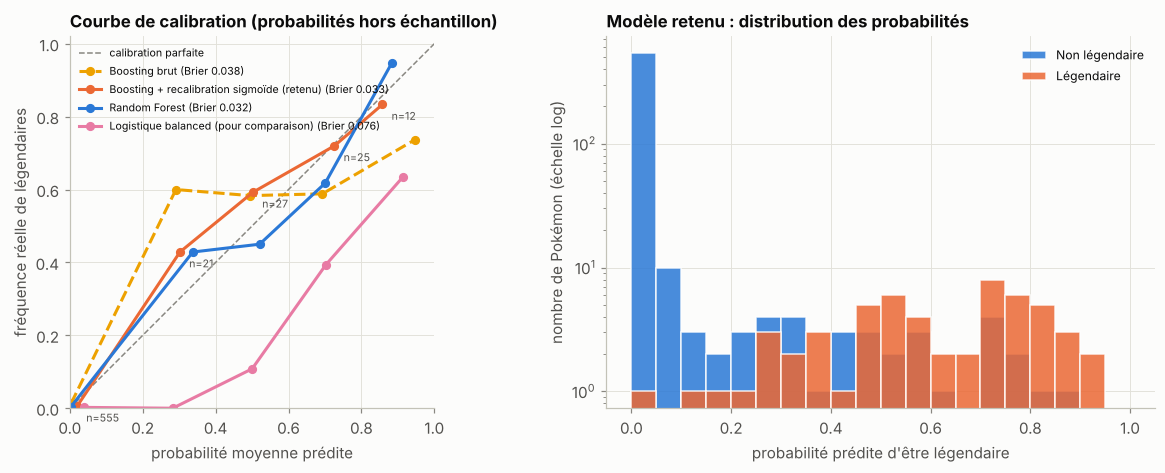

,Brier,log-loss,proba moyenne prédite,taux réel
Boosting brut,0.04,0.13,0.09,0.09
Boosting + recalibration sigmoïde (retenu),0.03,0.11,0.09,0.09
Random Forest,0.03,0.14,0.09,0.09
Logistique balanced (pour comparaison),0.08,0.27,0.21,0.09


In [50]:
gb_final = meilleurs["Gradient boosting"]
calib_modeles = {
    "Boosting brut": gb_final,
    "Boosting + recalibration sigmoïde (retenu)": CalibratedClassifierCV(gb_final, method="sigmoid", cv=5),
    "Random Forest": meilleurs["Random Forest"],
    "Logistique balanced (pour comparaison)": make_pipe(LogisticRegression(class_weight="balanced", max_iter=5000)),
}
oof = {n: cross_val_predict(m, X_train, y_train, cv=CV5, method="predict_proba")[:, 1]
       for n, m in calib_modeles.items()}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw=dict(width_ratios=[1.2, 1]))
ax = axes[0]
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1, label="calibration parfaite")
for (n, p), c, ls in zip(oof.items(), [SERIES[3], SERIES[1], SERIES[0], SERIES[4]], ["--", "-", "-", "-"]):
    frac, moy = calibration_curve(y_train, p, n_bins=5, strategy="uniform")
    ax.plot(moy, frac, marker="o", ms=5, color=c, ls=ls, label=f"{n} (Brier {brier_score_loss(y_train, p):.3f})")
    if n == "Boosting + recalibration sigmoïde (retenu)":
        eff = np.histogram(p, bins=np.linspace(0, 1, 6))[0]
        for x_, y_, e in zip(moy, frac, eff[eff > 0]):
            ax.annotate(f"n={e}", (x_, y_), xytext=(6, -10), textcoords="offset points", fontsize=7, color=INK_2)
ax.set(title="Courbe de calibration (probabilités hors échantillon)", xlabel="probabilité moyenne prédite",
       ylabel="fréquence réelle de légendaires", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(fontsize=7, loc="upper left")
ax.set_aspect("equal")

ax = axes[1]
p = oof["Boosting + recalibration sigmoïde (retenu)"]
bins = np.linspace(0, 1, 21)
for k in (0, 1):
    ax.hist(p[y_train.values == k], bins=bins, color=LEG_PALETTE[k], alpha=0.85, label=LEG_LABELS[k],
            edgecolor="white", linewidth=1)
ax.set_yscale("log")
ax.set(title="Modèle retenu : distribution des probabilités", xlabel="probabilité prédite d'être légendaire",
       ylabel="nombre de Pokémon (échelle log)")
ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "25_calibration")
plt.show()

pd.DataFrame({"Brier": {n: brier_score_loss(y_train, p) for n, p in oof.items()},
              "log-loss": {n: log_loss(y_train, p) for n, p in oof.items()},
              "proba moyenne prédite": {n: p.mean() for n, p in oof.items()}}).assign(
    **{"taux réel": y_train.mean()}).round(3)

**Lecture : la calibration change notre choix**

- **Le boosting brut est trop sûr de lui** dans les probabilités hautes. Dans la dernière tranche (80–100 %), il annonce en moyenne environ 95 %, alors que seulement environ 75 % de ces Pokémon sont légendaires : sa courbe passe **sous la diagonale**.
  - **Pourquoi :** le boosting ajoute des arbres qui « poussent » les scores des exemples d'entraînement vers 0 ou 1. Avec peu de légendaires, il devient trop confiant.
  - **Sa moyenne globale reste juste** (8,7 %), ce qui montre qu'une bonne moyenne ne garantit **pas** une bonne calibration tranche par tranche.
- **Après recalibration sigmoïde, la courbe colle beaucoup mieux à la diagonale.** Le Brier et la log-loss baissent aussi (log-loss d'environ 0,13 → 0,11).
- **La logistique pondérée surestime fortement** les probabilités : sa moyenne prédite (environ 21 %) vaut **plus du double** du taux réel. C'est le décalage de $\ln w$ démontré en 3.4.
- **Décision : le modèle final est le boosting recalibré.** L'appli **affiche** la probabilité, et c'est précisément ce que la recalibration améliore. Elle conserve à peu près l'ordre des scores, donc la PR-AUC et la ROC-AUC bougent peu. Le coût est négligeable : 5 boostings au lieu d'un, soit quelques millisecondes par prédiction.
- **Limite :** avec 56 légendaires, les tranches hautes reposent sur 12 à 27 Pokémon chacune (voir les effectifs `n=` sur la figure). La calibration est donc vérifiée **à gros grain** seulement.

### 3.10 Choix du seuil de décision

Le modèle donne une probabilité $p$. Pour afficher un verdict « légendaire probable », il faut un **seuil** $t$ : on dit « légendaire » si $p \geq t$.

**0,5 n'a rien de spécial.** C'est le bon seuil si les deux erreurs ont le même coût **et** si les classes sont équilibrées, ce qui n'est pas notre cas.

On choisit $t$ sur les probabilités **hors échantillon du train** (jamais sur le test), en **maximisant le F1** : le meilleur compromis entre rappel et précision.

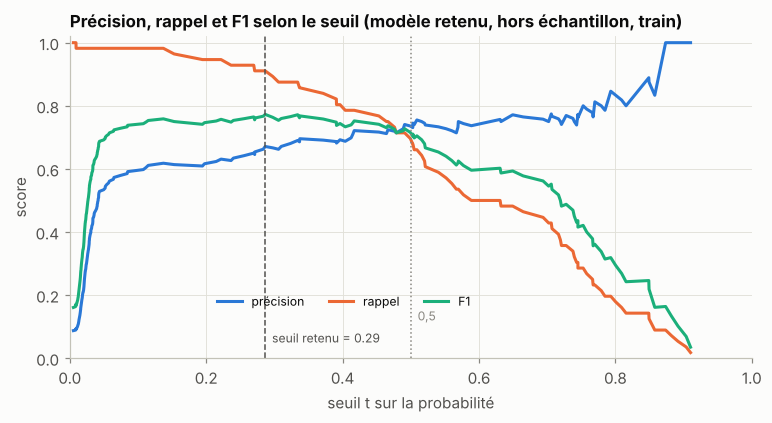

,"seuil 0,5",seuil 0.29
précision,0.73,0.67
rappel,0.68,0.91
F1,0.70,0.77


In [51]:
p_oof = oof["Boosting + recalibration sigmoïde (retenu)"]
prec, rec, seuils = precision_recall_curve(y_train, p_oof)
f1s = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
SEUIL = float(seuils[int(np.argmax(f1s))])

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(seuils, prec[:-1], color=SERIES[0], label="précision")
ax.plot(seuils, rec[:-1], color=SERIES[1], label="rappel")
ax.plot(seuils, f1s, color=SERIES[2], label="F1")
ax.axvline(SEUIL, color=INK_2, ls="--", lw=1)
ax.axvline(0.5, color=MUTED, ls=":", lw=1)
ax.text(SEUIL + 0.01, 0.05, f"seuil retenu = {SEUIL:.2f}", fontsize=8, color=INK_2)
ax.text(0.51, 0.12, "0,5", fontsize=8, color=MUTED)
ax.set(title="Précision, rappel et F1 selon le seuil (modèle retenu, hors échantillon, train)",
       xlabel="seuil t sur la probabilité", ylabel="score", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower left", bbox_to_anchor=(0.2, 0.12), ncol=3, fontsize=8)
save_fig(fig, "26_choix_seuil")
plt.show()

pd.DataFrame({t_nom: {"précision": precision_score(y_train, p_oof >= t),
                      "rappel": recall_score(y_train, p_oof >= t), "F1": f1_score(y_train, p_oof >= t)}
              for t_nom, t in [("seuil 0,5", 0.5), (f"seuil {SEUIL:.2f}", SEUIL)]}).round(3)

**Lecture.** Le F1 est maximal pour un seuil d'environ **0,3**, avec un **plateau** assez large autour (F1 d'environ 0,75–0,77). Au seuil de 0,5, le F1 descend à environ 0,70. Le choix exact du seuil n'est donc pas critique. Abaisser le seuil sous 0,5 fait gagner du **rappel** pour une perte modérée de **précision**. C'est l'équivalent **explicite et maîtrisé** de ce que faisait `class_weight="balanced"`, avec un avantage : **la probabilité affichée reste calibrée**.

Dans l'appli, on affichera donc :
- la **probabilité** (en %, avec une barre) ;
- la mention **« légendaire probable »** quand elle dépasse le seuil retenu.

### 3.11 Évaluation finale sur le jeu de test (une seule fois)

On réentraîne le modèle retenu (boosting + total + recalibration sigmoïde) sur **tout le train**, puis on l'évalue **une seule fois** sur les 161 Pokémon du test, avec le seuil choisi en 3.10. On donne aussi, **à titre de comparaison**, les scores de la règle « total ≥ 570 » sur ce même test.

,accuracy,balanced acc.,précision,rappel,F1,ROC-AUC,PR-AUC,Brier
Modèle retenu (seuil 0.29),0.97,0.95,0.77,0.93,0.84,0.99,0.94,0.02
Règle total ≥ 570,0.96,0.94,0.68,0.93,0.79,0.94,0.70,NaN


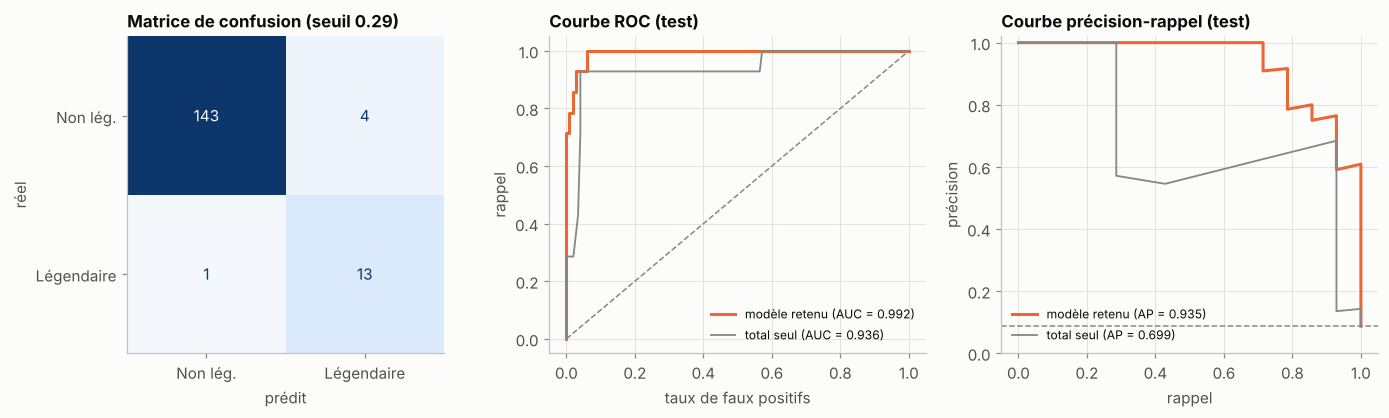

In [52]:
modele_legendaire = CalibratedClassifierCV(meilleurs["Gradient boosting"], method="sigmoid", cv=5)
modele_legendaire.fit(X_train, y_train)
p_test = modele_legendaire.predict_proba(X_test)[:, 1]
pred_test = (p_test >= SEUIL).astype(int)

def scores_bin(y, pred, score=None):
    d = {"accuracy": accuracy_score(y, pred), "balanced acc.": balanced_accuracy_score(y, pred),
         "précision": precision_score(y, pred), "rappel": recall_score(y, pred), "F1": f1_score(y, pred)}
    if score is not None:
        d.update({"ROC-AUC": roc_auc_score(y, score), "PR-AUC": average_precision_score(y, score)})
        if score.max() <= 1:
            d["Brier"] = brier_score_loss(y, score)
    return d

tot_t = X_test.sum(axis=1).values
display(pd.DataFrame({f"Modèle retenu (seuil {SEUIL:.2f})": scores_bin(y_test, pred_test, p_test),
                      "Règle total ≥ 570": scores_bin(y_test, tot_t >= 570, tot_t)}).T.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.9))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=["Non lég.", "Légendaire"]).plot(
    ax=axes[0], cmap=CMAP_SEQ, colorbar=False)
axes[0].set(title=f"Matrice de confusion (seuil {SEUIL:.2f})", xlabel="prédit", ylabel="réel")
axes[0].grid(False)
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[1].plot(fpr, tpr, color=SERIES[1], label=f"modèle retenu (AUC = {roc_auc_score(y_test, p_test):.3f})")
fpr2, tpr2, _ = roc_curve(y_test, tot_t)
axes[1].plot(fpr2, tpr2, color=MUTED, lw=1.2, label=f"total seul (AUC = {roc_auc_score(y_test, tot_t):.3f})")
axes[1].plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1)
axes[1].set(title="Courbe ROC (test)", xlabel="taux de faux positifs", ylabel="rappel")
axes[1].legend(fontsize=8, loc="lower right")
pr_c, rc_c, _ = precision_recall_curve(y_test, p_test)
axes[2].plot(rc_c, pr_c, color=SERIES[1], label=f"modèle retenu (AP = {average_precision_score(y_test, p_test):.3f})")
pr_t, rc_t, _ = precision_recall_curve(y_test, tot_t)
axes[2].plot(rc_t, pr_t, color=MUTED, lw=1.2, label=f"total seul (AP = {average_precision_score(y_test, tot_t):.3f})")
axes[2].axhline(y_test.mean(), color=MUTED, ls="--", lw=1)
axes[2].set(title="Courbe précision-rappel (test)", xlabel="rappel", ylabel="précision", ylim=(0, 1.02))
axes[2].legend(fontsize=8, loc="lower left")
fig.tight_layout()
save_fig(fig, "27_test_legendaire")
plt.show()

In [53]:
erreurs = df_test.assign(proba=p_test, prédit=pred_test)
erreurs = erreurs[erreurs["prédit"] != erreurs[TARGET_LEGENDARY]]
erreurs.assign(erreur=np.where(erreurs[TARGET_LEGENDARY] == 1, "faux négatif (légendaire raté)",
                               "faux positif (pris pour un légendaire)"))[
    ["name", "erreur", "proba", "base_total", "cluster_nom", *STATS]].sort_values("proba", ascending=False)

,name,erreur,proba,base_total,cluster_nom,hp,attack,defense,sp_attack,sp_defense,speed
281,Gardevoir,faux positif (pris pour un légendaire),0.53,618,Puissants / quasi-légendaires,68,85,65,165,135,100
64,Alakazam,faux positif (pris pour un légendaire),0.44,600,Puissants / quasi-légendaires,55,50,65,175,105,150
427,Lopunny,faux positif (pris pour un légendaire),0.42,580,Attaquants rapides,65,136,94,54,96,135
253,Sceptile,faux positif (pris pour un légendaire),0.36,630,Puissants / quasi-légendaires,70,110,75,145,85,145
789,Cosmoem,faux négatif (légendaire raté),0.07,400,Tanks défensifs,43,29,131,29,131,37


**Analyse des erreurs.** Le modèle ne fait que 5 erreurs sur 161, et elles étaient **prévisibles** d'après l'EDA et le clustering :

- **Les 4 faux positifs sont tous des méga-évolutions** : Alakazam (600), Gardevoir (618), Jungko (630) et Lockpin (580). Le dataset donne pour ces Pokémon les stats de leur forme méga, qui ont un **total de légendaire**. Pour les stats, ils sont indiscernables d'un légendaire. C'est une **limite des données**, pas du modèle.
- **Le seul faux négatif est Cosmovum** (400) : un **cocon** légendaire au profil de « tank défensif » très faible. Rien dans ses stats ne le distingue d'un Pokémon ordinaire, et son statut relève de l'**histoire du jeu**.

**Comparaison CV / test.** Le test donne des scores un peu **meilleurs** que la validation croisée : PR-AUC d'environ 0,94 contre 0,80. Ce n'est **pas** le signe d'un problème : avec seulement **14 légendaires** dans le test, chaque légendaire pèse environ 7 points de rappel, et ce découpage-ci se trouve être favorable. L'estimation la plus fiable de la performance reste **celle de la validation croisée répétée**. Il n'y a **pas de surapprentissage** : un modèle surappris ferait **moins** bien sur le test.

**Comparaison avec la règle simple.** La règle « total ≥ 570 » obtient le **même rappel** (13 légendaires sur 14), mais une **précision plus faible** (0,68 contre 0,77) : elle se trompe sur plus de pseudo-légendaires. L'apport du modèle est double :
1. il donne une **probabilité calibrée**, là où la règle ne donne qu'un oui/non ;
2. il distingue mieux les Pokémon forts mais non légendaires, grâce à la **répartition** des stats.

### 3.12 Variante : ajouter la taille et le poids aidait-il ?

On compare, sur les mêmes 50 plis répétés, le boosting retenu avec les **6 stats + total** et avec **6 stats + total + taille + poids**. Pour la variante, le prétraitement applique l'imputation par la médiane, `log1p` puis la standardisation, **dans le pipeline**.

In [54]:
X_train_phys = get_X(df_train, "stats_phys")
gb_params = meilleurs["Gradient boosting"]["model"].get_params()
variantes = {}
for var, prep, X_ in [("6 stats + total", make_preprocessor("stats", with_total=True), X_train),
                      ("6 stats + total + taille + poids", make_preprocessor("stats_phys", with_total=True), X_train_phys)]:
    # Pipeline de scikit-learn ici : celui d'imbalanced-learn refuse un Pipeline imbriqué
    from sklearn.pipeline import Pipeline as SkPipeline
    pipe = SkPipeline([("prep", prep), ("model", HistGradientBoostingClassifier(**gb_params))])
    r = cross_validate(pipe, X_, y_train, cv=RCV, scoring=score_rep, n_jobs=-1)
    variantes[var] = {k: (r[f"test_{k}"] * (1 if k in ("pr_auc", "roc_auc") else -1)) for k in score_rep}
d = variantes["6 stats + total + taille + poids"]["pr_auc"] - variantes["6 stats + total"]["pr_auc"]
display(pd.DataFrame({v: {k: f"{x.mean():.3f} ± {x.std():.3f}" for k, x in s.items()} for v, s in variantes.items()}).T)
print(f"Gain de PR-AUC apporté par taille + poids : {d.mean():+.3f} (positif sur {(d > 0).mean():.0%} des plis)")

,pr_auc,roc_auc,brier,log_loss
6 stats + total,0.795 ± 0.096,0.966 ± 0.031,0.036 ± 0.012,0.128 ± 0.047
6 stats + total + taille + poids,0.850 ± 0.078,0.973 ± 0.028,0.032 ± 0.011,0.111 ± 0.046


Gain de PR-AUC apporté par taille + poids : +0.055 (positif sur 70% des plis)


**Lecture : cette fois, la variante aide.** Pour le boosting, ajouter la taille et le poids fait passer la PR-AUC d'environ 0,80 à 0,85, et améliore la log-loss. Le gain est positif sur environ 70 % des plis : il est **modeste mais plutôt réel**. Pour la logistique, la même variante ne changeait rien.

**Explication probable.** Le poids aide justement à séparer les **méga-évolutions**, nos principaux faux positifs, des légendaires. Une forme méga garde la **taille et le poids** du Pokémon de base, alors que les légendaires sont souvent très grands et très lourds (médiane de 120 kg contre 25 kg, voir 1.7).

**Décision pour l'appli.** On garde la version **6 stats + total**, parce que le cahier des charges impose les 6 stats comme seule entrée. La variante est une **piste d'amélioration** concrète : on pourrait ajouter des champs **optionnels** « taille » et « poids », que l'appli remplirait automatiquement quand on choisit un Pokémon existant.

### 3.13 Synthèse : prédiction du statut légendaire

| Élément | Choix et justification |
|---|---|
| Protocole | split stratifié 80/20 (test sous clé), validation croisée stratifiée 5 plis sur le train, `Pipeline` (total) → scaler → (SMOTE) → modèle |
| Critère principal | **PR-AUC** : indépendante du seuil, centrée sur la classe rare (hasard = 0,087). L'accuracy est trompeuse (91 % pour « toujours non ») |
| Référence | la règle « total ≥ 570 » est très forte (F1 ≈ 0,78), car les légendaires ont des totaux « ronds » |
| Déséquilibre | `class_weight` et SMOTE comparés : ils déplacent le seuil mais **ne classent pas mieux**, et ils **gonflent les probabilités** (logit décalé de ≈ ln w). Choix : pas de pondération, seuil explicite |
| Ingénierie de variable | **ajout du total** : inutile pour les modèles linéaires, décisif pour les arbres (frontières parallèles aux axes) |
| Modèle retenu | **gradient boosting + total, recalibré (sigmoïde)**, à égalité avec la Random Forest en PR-AUC, mais meilleure log-loss et ~7× plus rapide. Il bat SVM, logistique et k-NN sur 74 à 82 % des plis. k-NN écarté (mémorisation), arbre seul écarté (probabilités mal calibrées) |
| Calibration | le boosting brut est **trop confiant** au-dessus de 80 %. Une **recalibration sigmoïde** (Platt, CV 5 plis) le corrige (log-loss 0,13 → 0,11) : la probabilité affichée est fiable |
| Seuil | ≈ 0,3, choisi hors échantillon en maximisant le F1 (au lieu de 0,5) |
| Test (161 Pokémon) | ROC-AUC ≈ 0,99, PR-AUC ≈ 0,94, F1 ≈ 0,84 : 13 légendaires sur 14 trouvés, 4 faux positifs, tous des méga-évolutions |
| Interprétation | Vitesse, Att. Spé. et PV pèsent le plus, l'Attaque physique le moins (pseudo-légendaires) |
| Variante taille + poids | gain modeste (PR-AUC ≈ +0,05, sépare mieux les méga-évolutions), mais l'entrée de l'appli reste les 6 stats : c'est une piste d'amélioration |